# Engage2Value: Predict Purchase Value from User Sessions

## Problem Statement

The goal is to predict the `purchaseValue` (revenue) for each user session on an e-commerce platform (Google Merchandise Store data).

**Business Challenge**: 
Most sessions (≈79%) result in zero revenue. A small number of sessions generate very high value. Predicting revenue is difficult because of heavy zero-inflation, right-skew, and high variance.

**Competition Objective**: Explain the variace in target variable through R2.

**Business Objective**:  helping optimize marketing and engagement strategies. and I will use rmsle for percentage difference so business can understand which prediction is going how wrong.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary fildf.head()es to /kaggle/temp/, but they won't be saved outside of the current session

from sklearn.preprocessing import TargetEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_squared_log_error ,roc_auc_score, log_loss, classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression , f_classif
from sklearn.linear_model import RidgeCV
from lightgbm import LGBMRegressor
from sklearn.model_selection import  KFold, cross_val_score ,cross_validate ,train_test_split
import time

# chronological sorting 


import matplotlib.pyplot as plt 
import seaborn as sns

/kaggle/input/competitions/engage-2-value-from-clicks-to-conversions/sample_submission.csv
/kaggle/input/competitions/engage-2-value-from-clicks-to-conversions/train_data.csv
/kaggle/input/competitions/engage-2-value-from-clicks-to-conversions/test_data.csv


In [2]:
df = pd.read_csv("/kaggle/input/competitions/engage-2-value-from-clicks-to-conversions/train_data.csv")

df_test = pd.read_csv("/kaggle/input/competitions/engage-2-value-from-clicks-to-conversions/test_data.csv")

# EDA

In [3]:
df.shape

(116023, 52)

In [4]:
df.sample(5)

,trafficSource.isTrueDirect,purchaseValue,browser,device.screenResolution,trafficSource.adContent,trafficSource.keyword,screenSize,geoCluster,trafficSource.adwordsClickInfo.slot,device.mobileDeviceBranding,...,device.language,deviceType,userChannel,device.browserVersion,totalHits,device.screenColors,sessionStart,geoNetwork.continent,device.isMobile,new_visits
16050,NaN,95980000.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_4,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Referral,not available in demo dataset,62,not available in demo dataset,1483622617,Americas,False,NaN
34612,NaN,0.0,Chrome,not available in demo dataset,NaN,(not provided),medium,Region_1,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Organic Search,not available in demo dataset,1,not available in demo dataset,1515592432,Americas,False,1.0
4689,True,0.0,Safari,not available in demo dataset,NaN,NaN,medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Direct,not available in demo dataset,23,not available in demo dataset,1520184958,Europe,False,NaN
3100,True,176670000.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Referral,not available in demo dataset,18,not available in demo dataset,1492803636,Americas,False,NaN
42447,NaN,0.0,Safari,not available in demo dataset,NaN,(not provided),medium,Region_3,NaN,not available in demo dataset,...,not available in demo dataset,mobile,Organic Search,not available in demo dataset,2,not available in demo dataset,1496713679,Americas,True,1.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116023 entries, 0 to 116022
Data columns (total 52 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   trafficSource.isTrueDirect                    42890 non-null   object 
 1   purchaseValue                                 116023 non-null  float64
 2   browser                                       116023 non-null  object 
 3   device.screenResolution                       116023 non-null  object 
 4   trafficSource.adContent                       2963 non-null    object 
 5   trafficSource.keyword                         44162 non-null   object 
 6   screenSize                                    116023 non-null  object 
 7   geoCluster                                    116023 non-null  object 
 8   trafficSource.adwordsClickInfo.slot           4281 non-null    object 
 9   device.mobileDeviceBranding                   11

In [6]:
(df.isnull().mean()*100).sort_values(ascending=False).head(12)

trafficSource.adContent                         97.446196
trafficSource.adwordsClickInfo.slot             96.310214
trafficSource.adwordsClickInfo.adNetworkType    96.310214
trafficSource.adwordsClickInfo.isVideoAd        96.310214
trafficSource.adwordsClickInfo.page             96.310214
trafficSource.referralPath                      63.184886
trafficSource.isTrueDirect                      63.033192
trafficSource.keyword                           61.936857
totals.bounces                                  59.363230
new_visits                                      30.601691
pageViews                                        0.006895
device.screenResolution                          0.000000
dtype: float64

## Missing Value Check

There are some columns with very high missing values, especially ad-related and traffic-source columns.

* ad click columns are mostly missing because most users may not come from paid ads
* `referralPath` and `keyword` depend on the traffic source
* `totals.bounces` missing can mean the session was not bounced
* `new_visits` missing can mean the user is returning

I will check their business meaning and later decide whether to fill, convert into flags, bucket, or drop them.

## Target Value analysis 


<Axes: title={'center': 'Raw Purchase Value (>0)'}, ylabel='Frequency'>

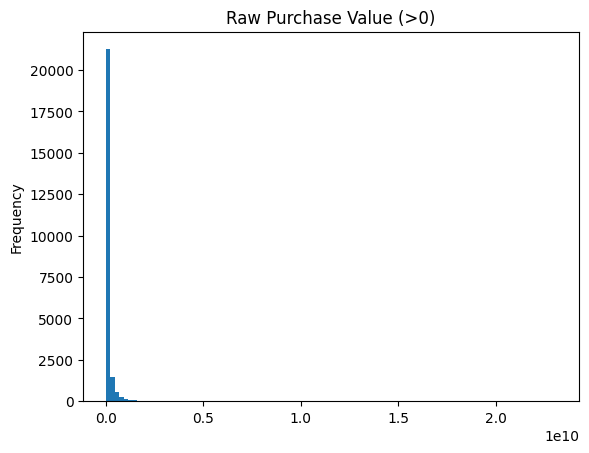

In [7]:
# Standard distribution heavily right skewed for ecommerce dataset so will do log 
df[df['purchaseValue'] > 0]['purchaseValue'].plot(kind='hist', bins=100, title="Raw Purchase Value (>0)")

<Axes: title={'center': 'Log Purchase Value (>0)'}, ylabel='Frequency'>

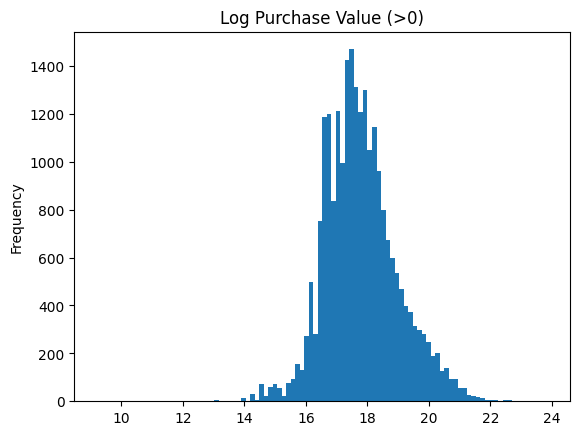

In [8]:
# Log-transformed distribution 
np.log1p(df[df['purchaseValue'] > 0]['purchaseValue']).plot(kind='hist', bins=100, title="Log Purchase Value (>0)")

on log normally distributed training a regressor model on this log transformed shape we stablize the variance and allow the model to minimze the errors bulk value of non zero transaction is centered around 18 and right tail is streching till 22-24 this are outliers 


Our paying customer base has a very predictable 'typical' spend range, but we have a long tail of 'whale' customers who spend exponentially more.

Because our typical buyers and our massive spenders behave so differently, our model is explicitly designed to isolate these high-value sessions rather than treating all transactions equally.

In [9]:
df['purchased'] = (df['purchaseValue'] > 0).astype(int)

In [10]:
# 1. We only want to look at sessions that actually made a purchase
buyers_df = df[df['purchaseValue'] > 0].copy()

> `purchased` is created directly from the target column `purchaseValue`, so it should be used for EDA and target analysis only. It must be removed from the feature set before model training, otherwise it will create target leakage.

<Axes: ylabel='count'>

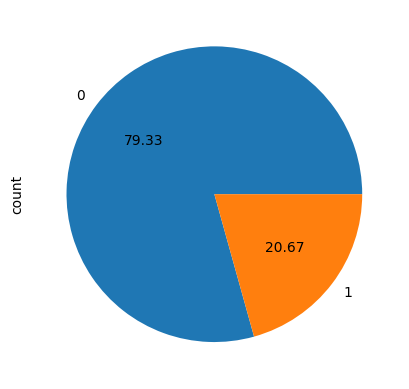

In [11]:
df['purchased'].value_counts().plot(kind='pie',autopct='%.2f')

## Purchase Class Distribution

~79% of sessions have no purchase, ~21% convert (purchaseValue > 0). Confirms the target is imbalanced/zero-inflated — informs the modeling approach should be two stage hurdel model conversion hurdle and Value prediction

## duplicates

In [12]:
df.duplicated().sum()

np.int64(236)

In [13]:
df = df.drop_duplicates()

## Define target and its distribution

In [14]:
df['purchaseValue'].describe()

count    1.157870e+05
mean     2.642244e+07
std      2.051726e+08
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.312950e+10
Name: purchaseValue, dtype: float64

 The target is zero-inflated rather than merely skewed. Because the majority of sessions have no purchase, the modeling problem is better framed as a two-part process: first estimate conversion probability, then estimate order value conditional on conversion. This better matches the business process and avoids a single regressor being dominated by the mass of zero outcomes.

# Seasonality 
is it season for this I will have to convert the time info data into proper time series data

In [15]:
def date_extraction(data):
    data = data.copy()

    data['date'] = pd.to_datetime(data['date'], format='%Y%m%d')
    data['quarter'] = pd.to_datetime(data['date'], format='%Y%m%d').dt.quarter
    data['date_year'] = data['date'].dt.year
    data['date_day'] = data['date'].dt.day
    data['date_month'] = data['date'].dt.month
    data['year_month'] = data['date'].dt.to_period('M')
    data['date_day_name'] = data['date'].dt.day_name()
    data['date_is_weekend'] = data['date_day_name'].isin(['Saturday', 'Sunday']).astype(int)
    
    # Regime Change Flag for Concept Drift
    # 1 if the session occurred during or after the August 2017 structural crash, else 0 added after EDA
    data['is_post_crash'] = (data['date'] >= '2017-08-01').astype(int)

    return data

In [16]:
df = date_extraction(df)
df_test = date_extraction(df_test)

In [17]:
df.shape

(115787, 61)

In [18]:
print(f"training data min date : {df['date'].min()}, Training data max date : {df['date'].max()}")

training data min date : 2016-08-01 00:00:00, Training data max date : 2018-04-30 00:00:00


In [19]:
print(f"test data min date: {df_test['date'].min()},test data max date:  {df_test['date'].max()}")

test data min date: 2016-08-01 00:00:00,test data max date:  2018-04-30 00:00:00


In [20]:
weekend_summary = df.groupby('date_is_weekend').agg(
    total_sessions=('sessionId', 'count'),
    conversion_rate=('purchased', 'mean'), # Stage 1: % of sessions that converted
    total_revenue=('purchaseValue', 'sum')
).reset_index()

In [21]:
# We filter out the zeros before taking the mean, otherwise the 79% of zeros drag the average down
aov_summary = df[df['purchaseValue'] > 0].groupby('date_is_weekend').agg(
    avg_order_value=('purchaseValue', 'mean') # Stage 2: How much buyers spend
).reset_index()


final_weekend_summary = weekend_summary.merge(aov_summary, on='date_is_weekend')

In [22]:
final_weekend_summary

,date_is_weekend,total_sessions,conversion_rate,total_revenue,avg_order_value
0,0,91924,0.221117,2.796927e+12,1.376034e+08
1,1,23863,0.145455,2.624481e+11,7.561167e+07


### Insight

Aggregating target metrics by day type reveals a massive behavioral shift between weekdays and weekends. The data strongly suggests a **corporate (B2B) purchasing environment** rather than standard retail e-commerce. 

* **Traffic Volume:** Weekdays drive nearly **4x more traffic** (91.9k sessions) compared to weekends (23.8k sessions).
* **Conversion Rate:** Users are significantly more likely to convert during the workweek (**22.1%**) than on the weekend (14.5%).
* **Average Order Value (AOV):** After adjusting for the standard $10^6$ analytics multiplier, weekday buyers spend almost double (**~137**) what weekend buyers spend (**~75**).

**Key Takeaway:** Our most valuable transactions occur during standard business hours, likely driven by institutional buyers. Weekend traffic represents lower-intent, casual browsing.

In [23]:
# Group by your device column to get total sessions and conversion rate
device_conversion_rate = df.groupby('deviceType').agg(
    total_sessions=('sessionId', 'count'),
    conversion_rate=('purchased', 'mean') 
).reset_index()

In [24]:
# Filter the dataframe so purchaseValue > 0, then group by the device column
device_AOV = df[df['purchaseValue'] > 0].groupby('deviceType').agg(
    avg_order_value=('purchaseValue', 'mean') # Calculate the average
).reset_index()

In [25]:
device_report = device_conversion_rate.merge(device_AOV, on='deviceType')
device_report

,deviceType,total_sessions,conversion_rate,avg_order_value
0,desktop,86281,0.251736,1.353516e+08
1,mobile,25818,0.067782,5.771710e+07
2,tablet,3688,0.088666,5.667829e+07


### Insight: Device Usage Confirms B2B Hypothesis

Triangulating our temporal findings with technological features confirms the enterprise nature of this platform. 

* **The Desktop Dominance:** Desktop users account for the vast majority of traffic and convert at an exceptional **25.1%**. 
* **The Mobile Drop-off:** Mobile and Tablet traffic converts at a fraction of the rate (~6-8%).
* **Value Discrepancy:** When purchases are made, Desktop Average Order Value (~ 135) is more than double that of Mobile (~ 57).

**Key Takeaway:** The platform's revenue engine is driven by high-intent desktop users, further validating the hypothesis that these are institutional or corporate buyers rather than retail consumers.

### Quarter

In [26]:
monthly_quality = df.groupby('year_month').agg(
    total_sessions=('sessionId', 'count'),
    conversion_rate=('purchased', 'mean') 
)
print(monthly_quality)

            total_sessions  conversion_rate
year_month                                 
2016-08               6926         0.250650
2016-09               6251         0.217405
2016-10               8200         0.168659
2016-11               9605         0.149193
2016-12               7725         0.288026
2017-01               5812         0.194425
2017-02               5419         0.201329
2017-03               6321         0.221168
2017-04               6200         0.234355
2017-05               6455         0.275600
2017-06               5999         0.250375
2017-07               6723         0.242749
2017-08               4145         0.260072
2017-09               3735         0.166533
2017-10               4079         0.145379
2017-11               3839         0.123209
2017-12               4043         0.152609
2018-01               3364         0.145065
2018-02               3432         0.136364
2018-03               4065         0.201968
2018-04               3449      

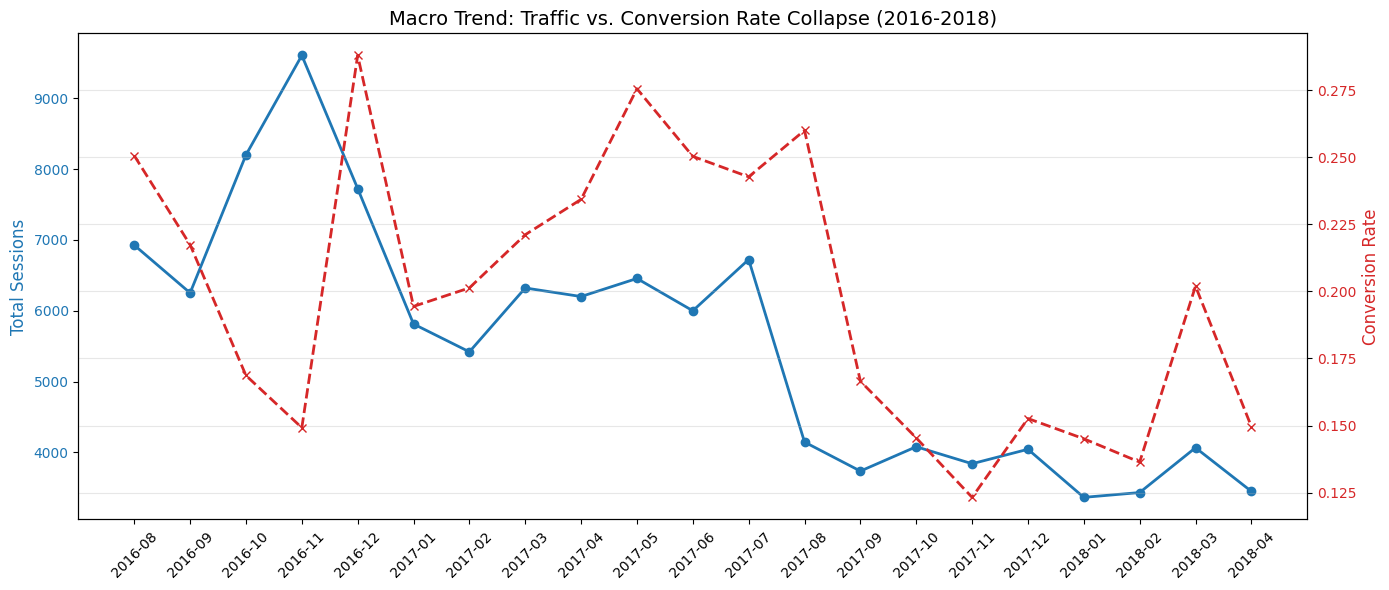

In [27]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot Total Sessions on the primary (left) Y-axis
ax1.plot(monthly_quality.index.astype(str), monthly_quality['total_sessions'], 
         color='tab:blue', marker='o', linewidth=2)
ax1.set_ylabel('Total Sessions', color='tab:blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.tick_params(axis='x', rotation=45) # Rotate dates for readability

# Create a twin axis sharing the same X-axis
ax2 = ax1.twinx()

# Plot Conversion Rate on the secondary (right) Y-axis
ax2.plot(monthly_quality.index.astype(str), monthly_quality['conversion_rate'], 
         color='tab:red', marker='x', linestyle='dashed', linewidth=2)
ax2.set_ylabel('Conversion Rate', color='tab:red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Macro Trend: Traffic vs. Conversion Rate Collapse (2016-2018)', fontsize=14)
plt.grid(True, alpha=0.3)
fig.tight_layout() # Prevents label clipping
plt.show()

###  Anomaly Detection: The Q3 2017 Structural Collapse

The timeline reveals a massive, permanent structural break in platform behavior starting in August 2017. 

* **Traffic Drop:** Total sessions abruptly halved in August 2017, dropping from previous highs to around 4,000 sessions.
* **Quality Degradation:** The conversion rate did not stabilize; following the traffic drop, it plummeted to lows near 12.5% by late 2017.

**Business Implication:** This is not standard seasonality. A dual-collapse of this magnitude indicates a major external event—such as a slashed marketing budget, a broken Google Analytics tracking tag, or a strategic business shift. Any model we train must account for this "regime change" in the data.

<Axes: xlabel='year_month'>

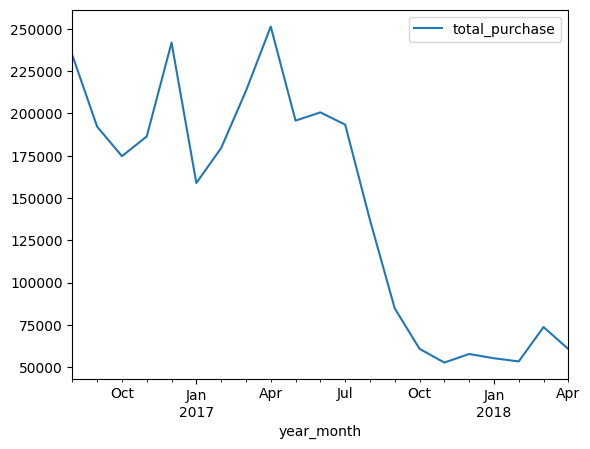

In [28]:
monthly_totals = df.groupby('year_month').agg(
    total_purchase=('purchaseValue' , 'sum')
)/1000000
monthly_totals.plot(kind='line')


Pivot Table Structure:
deviceType    desktop    mobile   tablet
year_month                              
2016-08     228354.14   3058.35  3028.16
2016-09     188478.29   3055.90   687.36
2016-10     163278.35  10423.89  1065.55
2016-11     175581.22   9654.87  1213.82
2016-12     229966.61   8993.62  2942.66


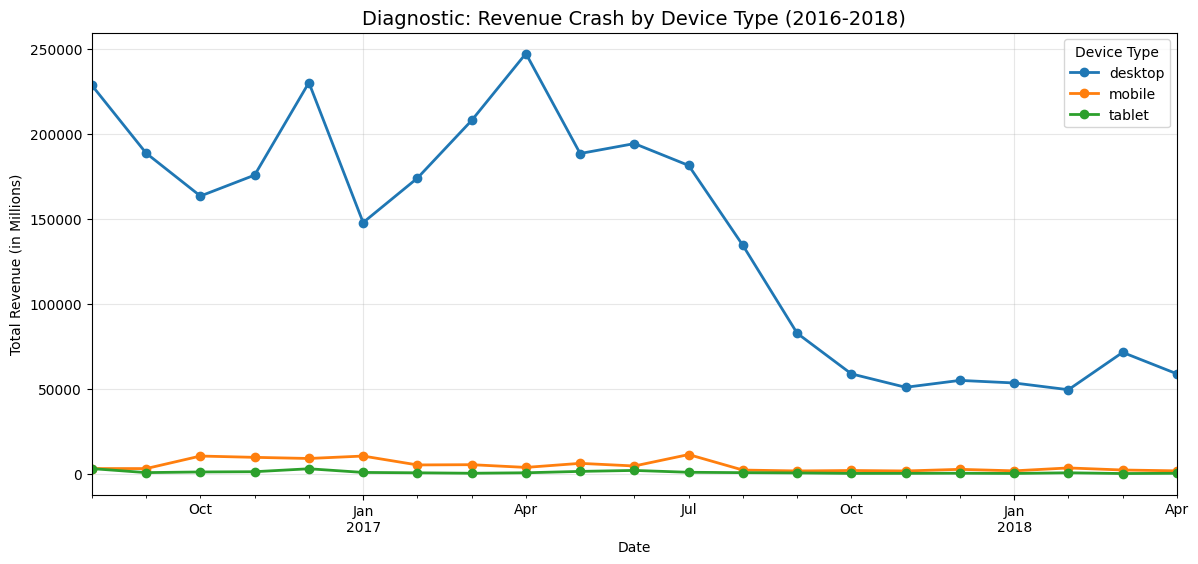

In [29]:
device_revenue_pivot = df.pivot_table(
    index='year_month', 
    columns='deviceType', 
    values='purchaseValue', 
    aggfunc='sum'
) / 1000000  # Adjusting for the analytics multiplier

# 2. Display the raw table to see the structure
print("Pivot Table Structure:")
print(device_revenue_pivot.head())

# 3. Plot the pivot table
# Pandas automatically plots a separate line for each column in a pivot table!
device_revenue_pivot.plot(kind='line', figsize=(14, 6), marker='o', linewidth=2)

plt.title('Diagnostic: Revenue Crash by Device Type (2016-2018)', fontsize=14)
plt.ylabel('Total Revenue (in Millions)')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)
plt.legend(title='Device Type')
plt.show()

Pivot Table Structure:
trafficSource.medium     (none)  (not set)  affiliate      cpc      cpm  \
year_month                                                                
2016-08                99838.74        NaN     139.44  4278.18  2258.02   
2016-09                99711.26        NaN       0.00  7055.99  4806.03   
2016-10               111260.58        NaN       9.99  2973.18   965.91   
2016-11               116959.33        NaN       0.00  2560.90  2742.14   
2016-12               146820.42        NaN       0.00  5768.01  1658.22   

trafficSource.medium   organic  referral  
year_month                                
2016-08               60030.65  67895.62  
2016-09               33579.75  47068.52  
2016-10               28782.49  30775.64  
2016-11               22456.23  41731.31  
2016-12               22647.16  65009.08  


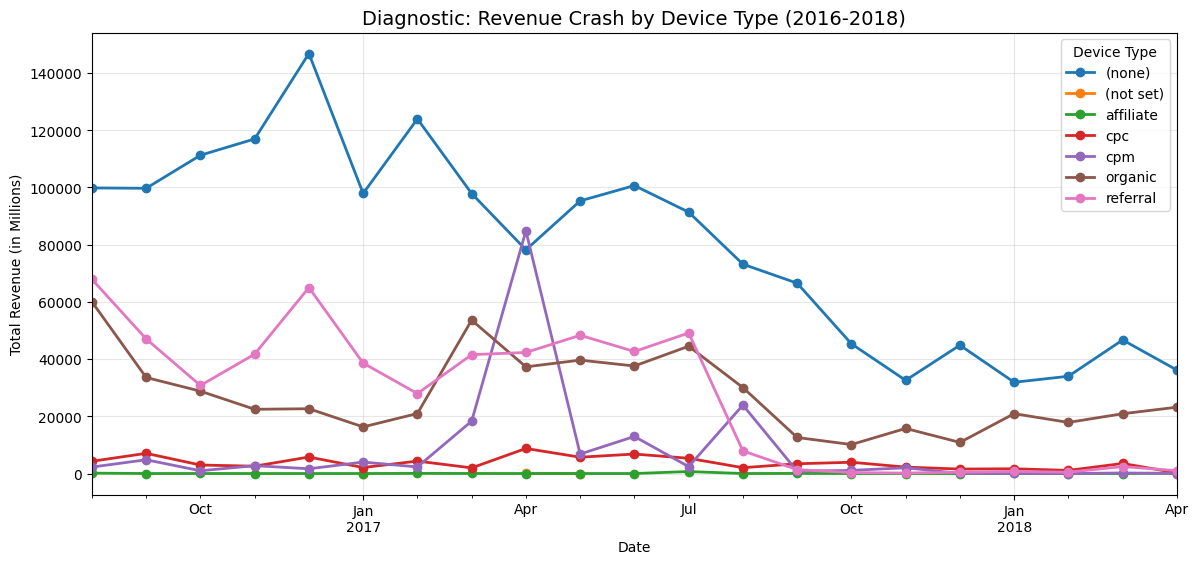

In [30]:
device_revenue_pivot = df.pivot_table(
    index='year_month', 
    columns='trafficSource.medium', 
    values='purchaseValue', 
    aggfunc='sum'
) / 1000000  

# 2. Display the raw table to see the structure
print("Pivot Table Structure:")
print(device_revenue_pivot.head())

# 3. Plot the pivot table
device_revenue_pivot.plot(kind='line', figsize=(14, 6), marker='o', linewidth=2)

plt.title('Diagnostic: Revenue Crash by Device Type (2016-2018)', fontsize=14)
plt.ylabel('Total Revenue (in Millions)')
plt.xlabel('Date')
plt.grid(True, alpha=0.3)
plt.legend(title='Device Type')
plt.show()

### Diagnostic: The Traffic Source Collapse

Pivoting total revenue by `trafficSource.medium` reveals that the August 2017 crash was isolated to specific acquisition channels, not a platform-wide failure.

* **The Primary Drivers:** Historically, the business relied almost entirely on **Direct (`none`)** and **Referral** traffic to generate revenue. Paid campaigns (`cpc`, `cpm`) contributed essentially zero value.
* **The Collapse:** After July 2017, Referral revenue flatlined completely, while Direct revenue entered a massive, permanent decline. 
* **Business Implication:** A major B2B enterprise partner likely broke a referral link, or a critical tracking tag was removed from the primary URL.

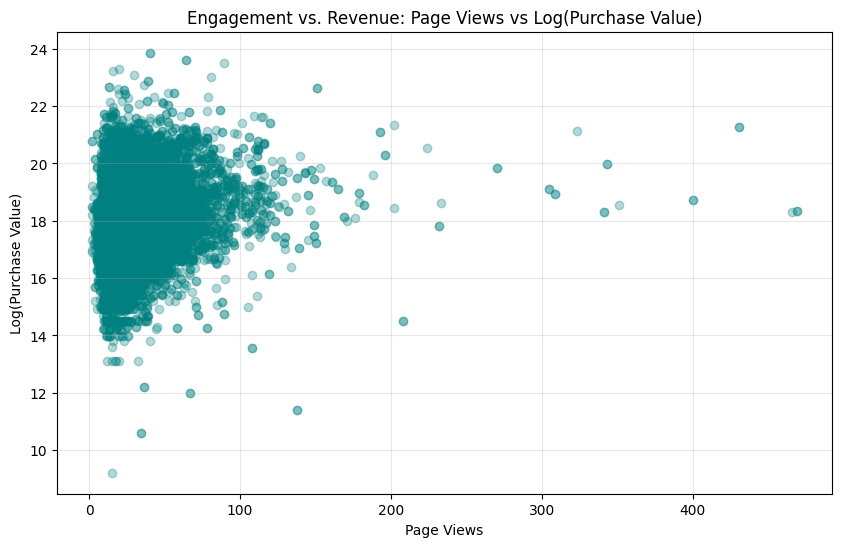

Correlation between Page Views and Log Revenue: 0.231


In [31]:
# 2. Create the log-transformed target for statistical stability
buyers_df['log_revenue'] = np.log1p(buyers_df['purchaseValue'])

# 3. Create a scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(buyers_df['pageViews'], buyers_df['log_revenue'], alpha=0.3, color='teal')
plt.title('Engagement vs. Revenue: Page Views vs Log(Purchase Value)')
plt.xlabel('Page Views')
plt.ylabel('Log(Purchase Value)')
plt.grid(True, alpha=0.3)
plt.show()

# 4. Check the Pearson correlation coefficient
correlation = buyers_df['pageViews'].corr(buyers_df['log_revenue'])
print(f"Correlation between Page Views and Log Revenue: {correlation:.3f}")

In [32]:
# 1. Isolate numerical columns for the correlation matrix
num_df = df.select_dtypes(include=['int64', 'float64'])
corr_matrix = num_df.corr()

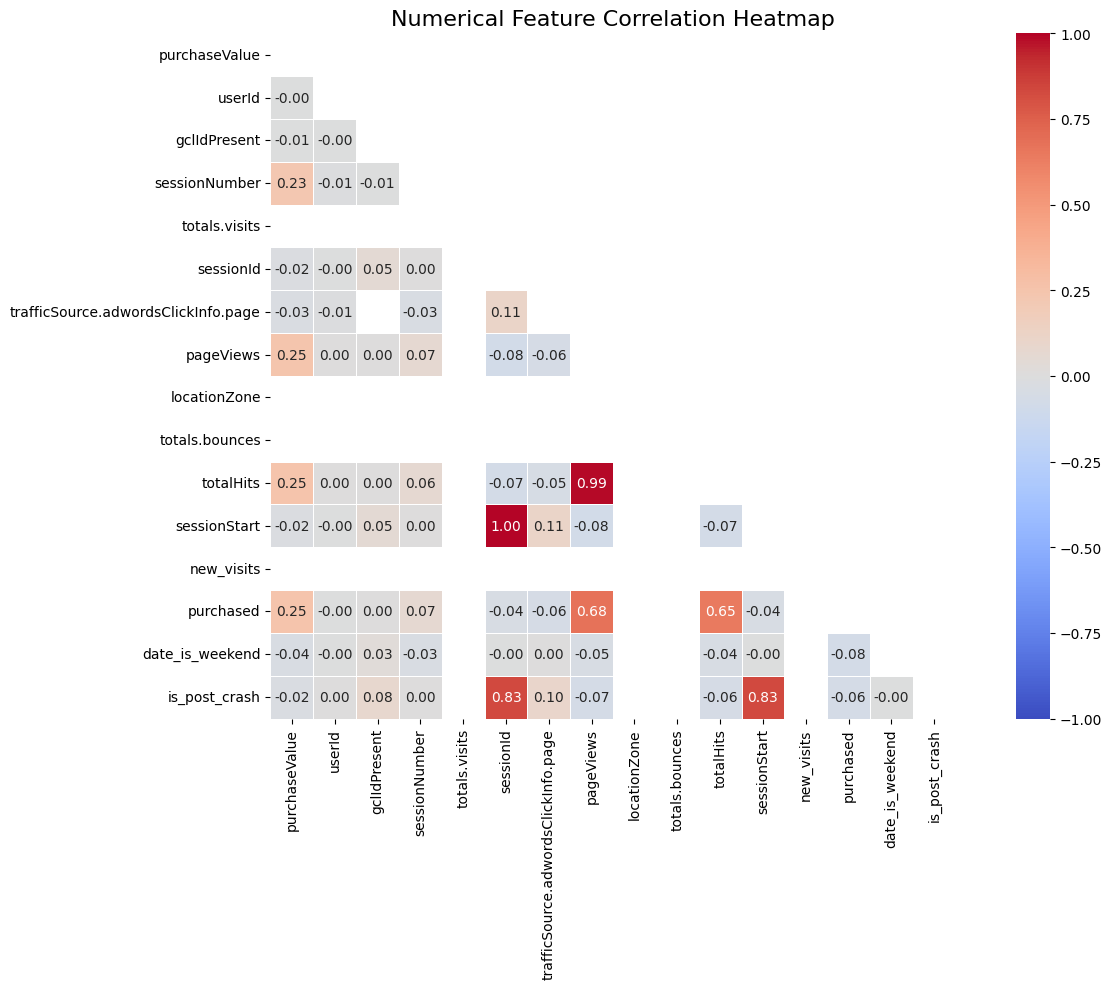

In [33]:
# 2. Create a mask to hide the upper triangle (removes mirrored duplicate info)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 3. Plot the heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, square=True, linewidths=.5)
plt.title('Numerical Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

### Correlation Diagnostics & Feature Behaviour

Evaluating our numerical features against both stages of our hurdle model (Conversion Probability vs. Transaction Magnitude) reveals critical behavioural patterns:

* **Multicollinearity Flag:** `pageViews` and `totalHits` share a near-perfect correlation (0.99). To prevent model instability and split-importance issues in our tree regressors, `totalHits` should be dropped. 
* **Engagement drives Conversion, not Value:** `pageViews` has a strong correlation (0.68) with the binary `purchased` flag, but a weak correlation (0.25) with actual `purchaseValue`. Browsing depth is a strong predictor of Stage 1 (whether they buy), but a weak predictor of Stage 2 (how much they spend).
* **The B2B Loyalty Signature:** `sessionNumber` has almost zero correlation (0.07) with conversion probability, but a notable positive correlation (0.23) with total revenue. Returning visitors do not convert more frequently, but when they do, they execute high-value transactions. This aligns with lengthy corporate procurement cycles.

In [34]:
categorical_cols = df.select_dtypes(include=['object'])
categorical_cols.nunique()

trafficSource.isTrueDirect                        1
browser                                          34
device.screenResolution                           1
trafficSource.adContent                          53
trafficSource.keyword                           566
screenSize                                        1
geoCluster                                        5
trafficSource.adwordsClickInfo.slot               3
device.mobileDeviceBranding                       1
device.mobileInputSelector                        1
trafficSource.campaign                           28
device.mobileDeviceMarketingName                  1
geoNetwork.networkDomain                          3
device.operatingSystemVersion                     1
device.flashVersion                               1
geoNetwork.region                               388
trafficSource                                   161
geoNetwork.networkLocation                        1
os                                               18
geoNetwork.s

In [35]:
df['trafficSource.referralPath'].isnull().sum()

np.int64(73099)

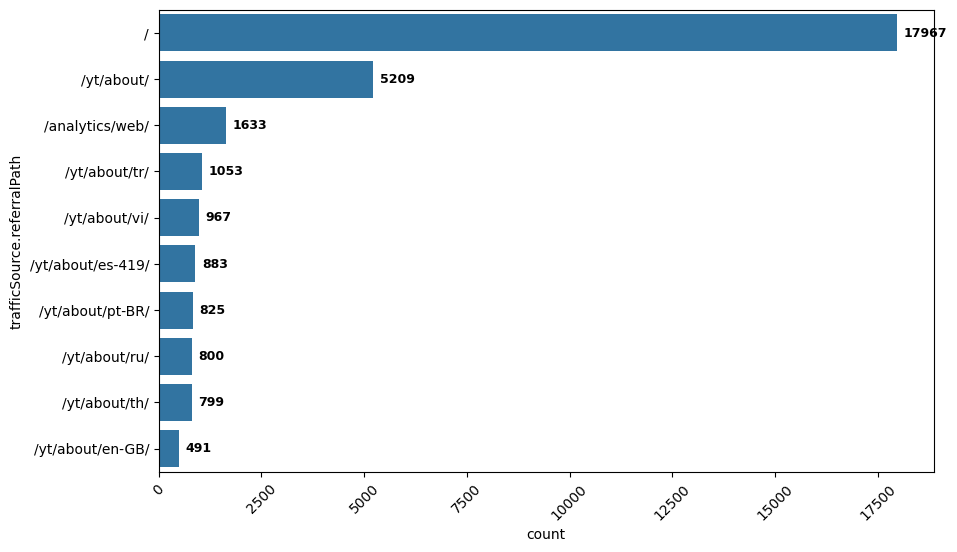

In [36]:
top_10 = df['trafficSource.referralPath'].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y='trafficSource.referralPath', 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

## Feature Engineering — `trafficSource.referralPath`
**Decision:** semantic bucket (locale variants → yt_about, /mail → mail etc.)
then frequency threshold (<100 sessions → Other). Drop original column.

**Why not target encode directly:** 941 values contain real duplicates and
one-off noise — bucketing by meaning is cleaner than encoding noisy raw strings.

In [37]:
path_counts = df['trafficSource.referralPath'].value_counts()

In [38]:
def process_referral_paths(dataframe, train_counts=None):
    paths = dataframe['trafficSource.referralPath'].fillna('Unknown').astype(str)
    
    if train_counts is None:
        train_counts = paths.value_counts().to_dict()
        
    path_frequencies = np.array([train_counts.get(x, 0) for x in paths])
    
    conditions = [
        paths == '/',
        paths.str.contains('/yt/about|/yt/advertise', na=False),
        paths.str.contains('/mail|/webmail|gmail', na=False),
        paths.str.startswith('/analytics', na=False),
        paths.str.contains('google-merchandise-store|/deal', na=False),
        paths.str.contains('/community|/a/google.com', na=False),
        path_frequencies >= 100
    ]
    
    choices = [
        'Home/Direct',
        'yt_about',
        'mail',
        'analytics',
        'merch_store',
        'google_internal',
        paths
    ]
    
    return np.select(conditions, choices, default='Other'), train_counts

def process_top_categories(dataframe, col_name, train_top_categories=None):
    if train_top_categories is None:
        train_top_categories = dataframe[col_name].value_counts().head(6).index
        
    return dataframe[col_name].where(dataframe[col_name].isin(train_top_categories), 'Other'), train_top_categories

### Think about it as a hierarchy:
continent → subContinent → country → city/metro

In [39]:
df['geoNetwork.city'].isnull().sum()

np.int64(0)

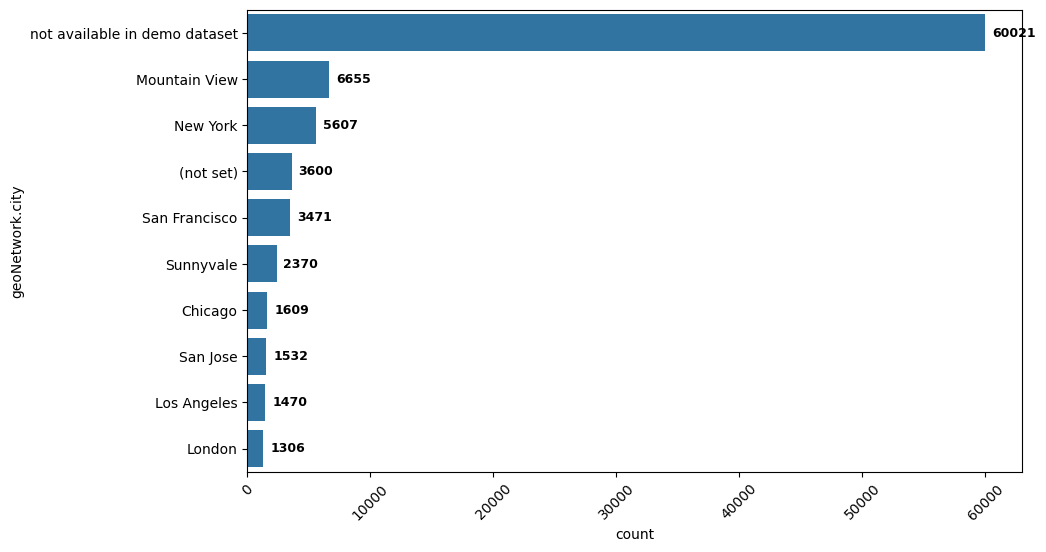

In [40]:
col = 'geoNetwork.city'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

isnull().sum() and a value_counts() scan for disguised-NaN placeholders.

Cardinality + long-tail shape.

Decide: does this column have exploitable semantic duplicates (→ bucket, like referralPath) or is every value a genuinely distinct entity (→ smooth/target-encode, like city)? .

Count + mean together, sorted by count.

In [41]:
zero_variance_features = ["device.screenResolution",
                    "screenSize" ,
                    "device.mobileDeviceBranding",
                    "device.mobileInputSelector",
                    "device.operatingSystemVersion",
                    "device.flashVersion",
                    "device.browserSize",
                    "device.browserVersion",
                    "device.mobileDeviceMarketingName",
                    "totals.visits" ,
                    "socialEngagementType" ,
                    'device.screenColors',
                    'device.language',
                    'device.mobileDeviceModel',
                    'browserMajor',
                    'trafficSource.adwordsClickInfo.isVideoAd',
                    'trafficSource.isTrueDirect',
                    'geoNetwork.networkLocation',
                    'locationZone'
                    
                         ] 

In [42]:
df = df.drop(columns=zero_variance_features, errors='ignore')
df_test = df_test.drop(columns=zero_variance_features, errors='ignore')

In [43]:
df['trafficSource.keyword'].isnull().sum()

np.int64(71729)

In [44]:
df['trafficSource.keyword'] = df['trafficSource.keyword'].fillna("Unknown")

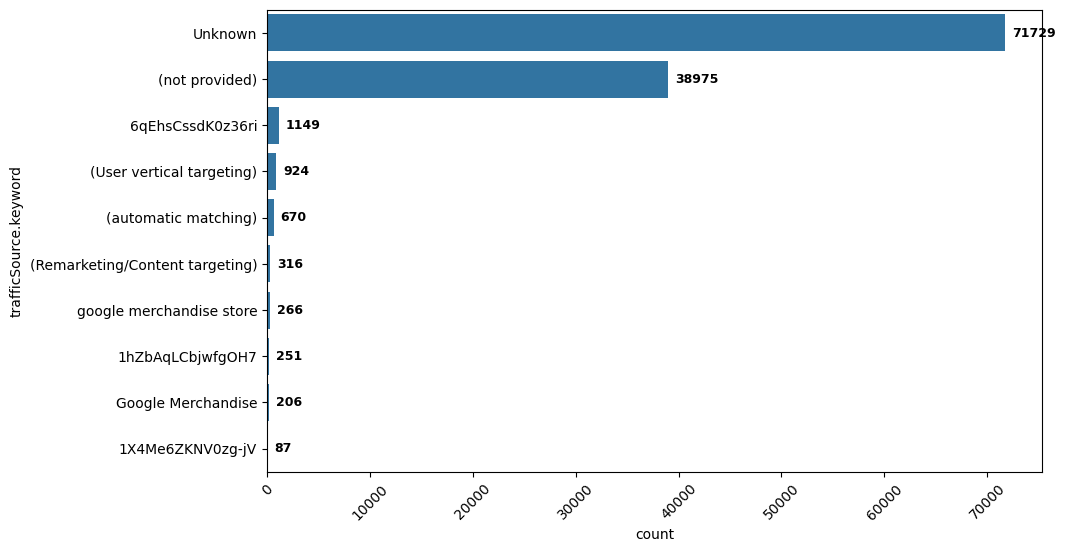

In [45]:
col = 'trafficSource.keyword'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [46]:
keyword_conversion = df.groupby('trafficSource.keyword').agg(
    total_sessions=('sessionId', 'count'),
    conversion_rate=('purchased', 'mean'),
    total_purchases=('purchased', 'sum')
)

# 2. Get the true average spend from the BUYERS dataset using RAW value
keyword_value = buyers_df.groupby('trafficSource.keyword').agg(
    avg_order_value=('purchaseValue', 'mean') # Raw dollars!
) / 1000000 # Adjusting Google's multiplier

# 3. Join them and look at the top keywords by traffic
keyword_report = keyword_conversion.join(keyword_value).sort_values(by='total_sessions', ascending=False)
keyword_report.head(20)

,total_sessions,conversion_rate,total_purchases,avg_order_value
trafficSource.keyword,,,,
Unknown,71729,0.238732,17124,NaN
(not provided),38975,0.150481,5865,95.983026
6qEhsCssdK0z36ri,1149,0.335944,386,92.913478
(User vertical targeting),924,0.000000,0,NaN
(automatic matching),670,0.007463,5,25.102000
(Remarketing/Content targeting),316,0.088608,28,66.558571
google merchandise store,266,0.353383,94,115.845851
1hZbAqLCbjwfgOH7,251,0.362550,91,64.843368
Google Merchandise,206,0.398058,82,190.020833


In [47]:
def process_keyword_buckets(dataframe, train_counts=None):
    
    cleaned_keywords = (
        dataframe["trafficSource.keyword"]
        .astype(str)
        .str.replace("+", "", regex=False)
        .str.strip()
    )
    
    if train_counts is None:
        train_counts = cleaned_keywords.value_counts().to_dict()
        
    
    keyword_counts = np.array(
    [train_counts.get(x, 0) for x in cleaned_keywords])
    
    # 3. Vectorized logic (lowercasing is done inline to save memory)
    cleaned_lower = cleaned_keywords.str.lower()
    conditions = [
        cleaned_lower.str.contains("google merch|merchandise store", na=False),
        cleaned_lower.str.contains("android hoodie|android toy", na=False),
        (keyword_counts > 200)
    ]
    
    choices = [
        "Google Merchandise Store",
        "Android Brand",
        cleaned_keywords
    ]
    
    return np.select(conditions, choices, default="Other"), train_counts

In [48]:
df["keyword_bucket"], train_counts_dict = process_keyword_buckets(df)
df_test["keyword_bucket"], _ = process_keyword_buckets(df_test, train_counts=train_counts_dict)

In [49]:
keyword_conversion = df.groupby('keyword_bucket').agg(
    total_sessions=('sessionId', 'count'),
    conversion_rate=('purchased', 'mean'),
    total_purchases=('purchased', 'sum')
)

# 2. Get the true average spend from the BUYERS dataset using RAW value
keyword_value = buyers_df.groupby('trafficSource.keyword').agg(
    avg_order_value=('purchaseValue', 'mean') # Raw dollars!
) / 1000000 # Adjusting Google's multiplier

# 3. Join them and look at the top keywords by traffic
keyword_report = keyword_conversion.join(keyword_value).sort_values(by='total_sessions', ascending=False)
keyword_report.head(20)

,total_sessions,conversion_rate,total_purchases,avg_order_value
keyword_bucket,,,,
Unknown,71729,0.238732,17124,NaN
(not provided),38975,0.150481,5865,95.983026
6qEhsCssdK0z36ri,1149,0.335944,386,92.913478
Other,1131,0.070734,80,NaN
(User vertical targeting),924,0.000000,0,NaN
(automatic matching),670,0.007463,5,25.102000
Google Merchandise Store,642,0.339564,218,NaN
(Remarketing/Content targeting),316,0.088608,28,66.558571
1hZbAqLCbjwfgOH7,251,0.362550,91,64.843368


In [50]:
df["keyword_bucket"].nunique()

9

In [51]:
df["geoNetwork.region"].isnull().sum()

np.int64(0)

In [52]:
df["geoNetwork.region"].nunique()

388

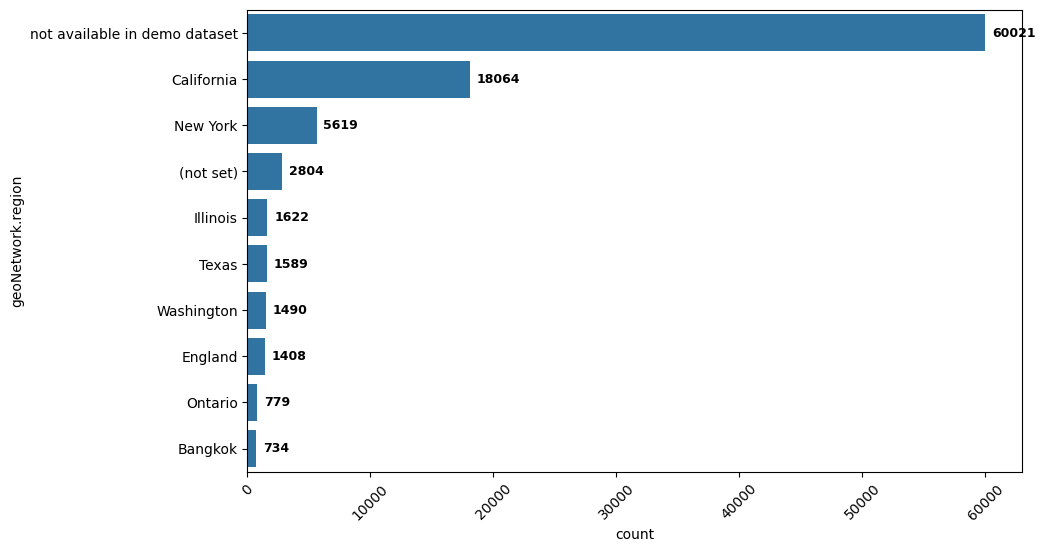

In [53]:
col = 'geoNetwork.region'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [54]:
df.groupby('geoNetwork.region').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

geoNetwork.region purchaseValue                            \
                                          count          mean      median   
0   not available in demo dataset         60021  2.152770e+07         0.0   
1                      California         18064  4.248046e+07         0.0   
2                        New York          5619  7.420519e+07  15190000.0   
3                       (not set)          2804  3.507265e+06         0.0   
4                        Illinois          1622  8.978184e+07  15990000.0   
5                           Texas          1589  3.849391e+07         0.0   
6                      Washington          1490  4.723566e+07         0.0   
7                         England          1408  2.361662e+06         0.0   
8                         Ontario           779  3.421397e+07         0.0   
9                         Bangkok           734  4.970572e+05         0.0   
10                    Maharashtra           726  3.508264e+04         0.0   
11                    Taipei City           639  1.289781e+06         0.0   
12                       Michigan           632  8.542440e+07  27190000.0   
13                      Karnataka           624  7.386859e+05         0.0   
14                  Massachusetts           601  7.075737e+07         0.0   
15                          Delhi           589  3.947199e+05         0.0   
16                       Istanbul           584  2.909247e+05         0.0   
17                    Ho Chi Minh           546  0.000000e+00         0.0   
18                     Tamil Nadu           504  9.869048e+04         0.0   
19                        Georgia           495  7.376012e+07         0.0   

   purchased        
        mean   sum  
0   0.153863  9235  
1   0.394652  7129  
2   0.546539  3071  
3   0.031740    89  
4   0.529593   859  
5   0.396476   630  
6   0.459060   684  
7   0.018466    26  
8   0.166881   130  
9   0.008174     6  
10  0.004132     3  
11  0.018779    12  
12  0.610759   386  
13  0.006410     4  
14  0.480865   289  
15  0.008489     5  
16  0.003425     2  
17  0.000000     0  
18  0.001984     1  
19  0.430303   213

## Reason for encoding

In [55]:
df['trafficSource'].isnull().sum()

np.int64(0)

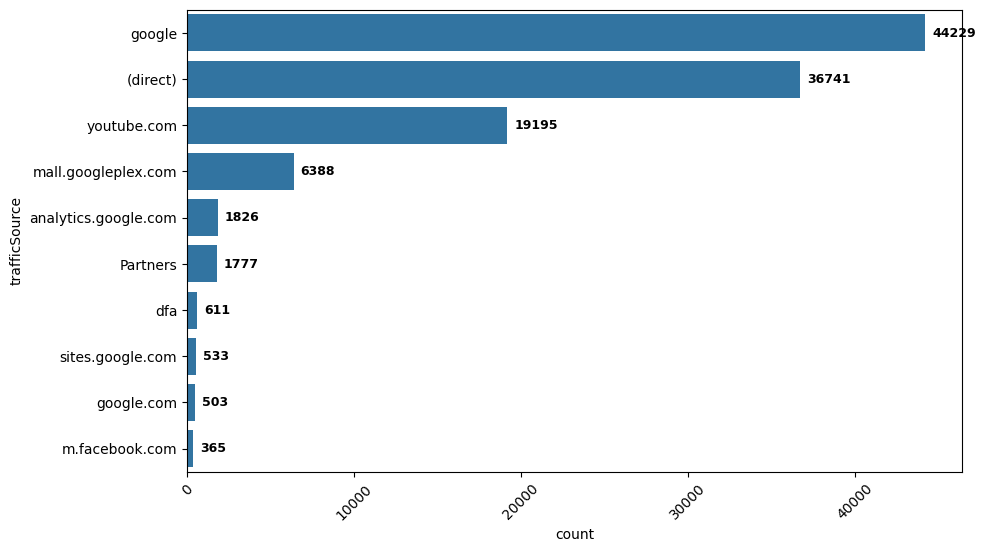

In [56]:
col = 'trafficSource'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [57]:
df.groupby('trafficSource').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

trafficSource purchaseValue                           purchased  \
                                    count          mean      median      mean   
0                    google         44229  1.491484e+07         0.0  0.152773   
1                  (direct)         36741  4.548504e+07         0.0  0.327291   
2               youtube.com         19195  3.525033e+04         0.0  0.001459   
3       mall.googleplex.com          6388  7.560430e+07  27180000.0  0.641359   
4      analytics.google.com          1826  1.285323e+04         0.0  0.001643   
5                  Partners          1777  6.340180e+05         0.0  0.011255   
6                       dfa           611  2.703626e+08         0.0  0.327332   
7          sites.google.com           533  1.774383e+07         0.0  0.168856   
8                google.com           503  1.681034e+06         0.0  0.031809   
9            m.facebook.com           365  9.058082e+05         0.0  0.030137   
10                    baidu           354  0.000000e+00         0.0  0.000000   
11          mail.google.com           253  1.437296e+08         0.0  0.494071   
12               reddit.com           234  6.811966e+04         0.0  0.008547   
13             facebook.com           231  7.638398e+06         0.0  0.116883   
14                     bing           227  7.324802e+06         0.0  0.171806   
15                qiita.com           187  0.000000e+00         0.0  0.000000   
16        groups.google.com           182  1.690929e+07         0.0  0.351648   
17                    yahoo           172  1.523733e+07         0.0  0.232558   
18                quora.com           159  3.267925e+05         0.0  0.012579   
19  siliconvalley.about.com           151  4.400464e+06         0.0  0.072848   

           
      sum  
0    6757  
1   12025  
2      28  
3    4097  
4       3  
5      20  
6     200  
7      90  
8      16  
9      11  
10      0  
11    125  
12      2  
13     27  
14     39  
15      0  
16     64  
17     40  
18      2  
19     11

In [58]:
def process_source_buckets(dataframe, train_counts=None):
    # 1. Clean strings uniformly
    source_clean = dataframe["trafficSource"].astype(str).str.lower().str.strip()
    
    # 2. Extract counts & handle unseen test sources safely (No Data Leakage)
    if train_counts is None:
        train_counts = source_clean.value_counts().to_dict()
        
    # Fast dictionary lookup (assigns 0 to brand-new sources in test set)
    source_counts = np.array([train_counts.get(x, 0) for x in source_clean])
    
    # 3. Vectorized logic
    conditions = [
        (source_clean == "google"),
        (source_clean == "(direct)"),
        (source_clean == "mall.googleplex.com"),
        source_clean.str.contains("facebook|reddit|quora|twitter|instagram|linkedin", na=False),
        source_clean.str.contains("bing|yahoo|baidu|duckduckgo", na=False),
        source_clean.str.contains("analytics.google|sites.google|mail.google|groups.google", na=False),
        (source_counts > 500)
    ]
    
    # 4. Choices matching original formatting
    choices = [
        "Google Organic",
        "Direct Traffic",
        "Googleplex Mall",
        "Social Media",
        "Other Search Engines",
        "Google Analytics/Internal",
        dataframe["trafficSource"] # Keeps original string name intact
    ]
    
    return np.select(conditions, choices, default="Other"), train_counts

In [59]:
df["source_bucket"], train_source_dict = process_source_buckets(df)
df_test["source_bucket"], _ = process_source_buckets(df_test, train_counts=train_source_dict)

In [60]:
df.groupby('source_bucket').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

source_bucket purchaseValue                            \
                                      count          mean      median   
0              Google Organic         44229  1.491484e+07         0.0   
1              Direct Traffic         36741  4.548504e+07         0.0   
2                 youtube.com         19195  3.525033e+04         0.0   
3             Googleplex Mall          6388  7.560430e+07  27180000.0   
4   Google Analytics/Internal          2794  1.750967e+07         0.0   
5                    Partners          1777  6.340180e+05         0.0   
6                       Other          1595  1.232147e+07         0.0   
7                Social Media          1121  3.569063e+06         0.0   
8        Other Search Engines           833  6.200000e+06         0.0   
9                         dfa           611  2.703626e+08         0.0   
10                 google.com           503  1.681034e+06         0.0   

   purchased         
        mean    sum  
0   0.152773   6757  
1   0.327291  12025  
2   0.001459     28  
3   0.641359   4097  
4   0.100931    282  
5   0.011255     20  
6   0.134796    215  
7   0.058876     66  
8   0.109244     91  
9   0.327332    200  
10  0.031809     16

In [61]:
df['locationCountry'].isnull().sum()

np.int64(0)

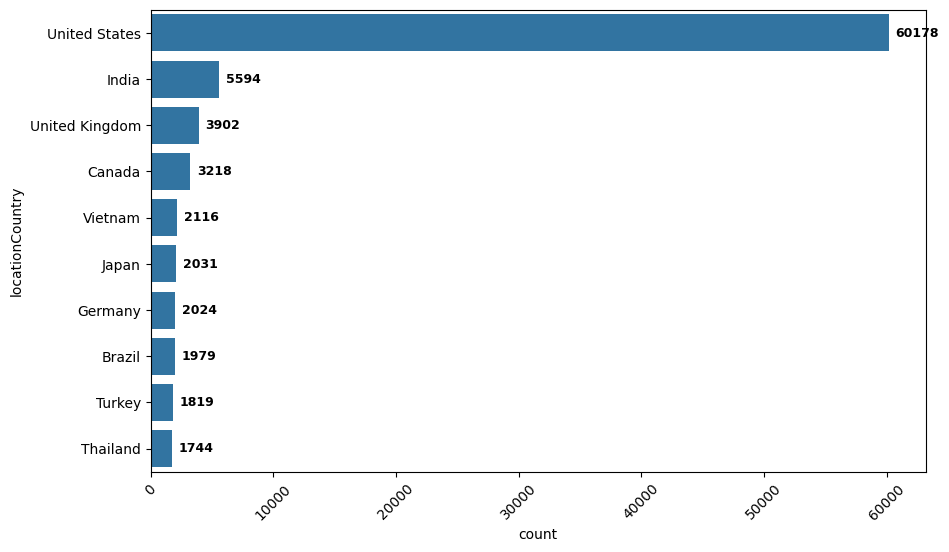

In [62]:
col = 'locationCountry'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [63]:
df.groupby('locationCountry').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

locationCountry purchaseValue                      purchased       
                           count          mean median      mean    sum
0    United States         60178  4.807586e+07    0.0  0.377031  22689
1            India          5594  3.459921e+05    0.0  0.004290     24
2   United Kingdom          3902  9.354152e+05    0.0  0.008457     33
3           Canada          3218  1.847622e+07    0.0  0.121504    391
4          Vietnam          2116  0.000000e+00    0.0  0.000000      0
5            Japan          2031  6.797011e+06    0.0  0.016741     34
6          Germany          2024  4.718923e+05    0.0  0.007411     15
7           Brazil          1979  1.179581e+06    0.0  0.012633     25
8           Turkey          1819  9.340297e+04    0.0  0.001100      2
9         Thailand          1744  5.830849e+05    0.0  0.008028     14
10          France          1729  8.540486e+05    0.0  0.008097     14
11          Mexico          1433  2.265932e+06    0.0  0.024424     35
12          Taiwan          1432  2.878897e+06    0.0  0.027235     39
13       Australia          1334  5.650202e+06    0.0  0.020990     28
14     Netherlands          1249  4.416253e+05    0.0  0.005604      7
15           Spain          1245  6.181365e+05    0.0  0.003213      4
16           Italy          1166  1.750343e+05    0.0  0.001715      2
17          Russia          1112  1.123201e+05    0.0  0.005396      6
18          Poland           964  4.771784e+05    0.0  0.006224      6
19       Indonesia           913  3.504874e+06    0.0  0.023001     21

## Encoding Reason 
> "Target encoded locationCountry (193 unique, all distinct, 20x within-continent
divergence proven — coarser continent column insufficient)."

In [64]:
df['geoNetwork.metro'].isnull().sum()

np.int64(0)

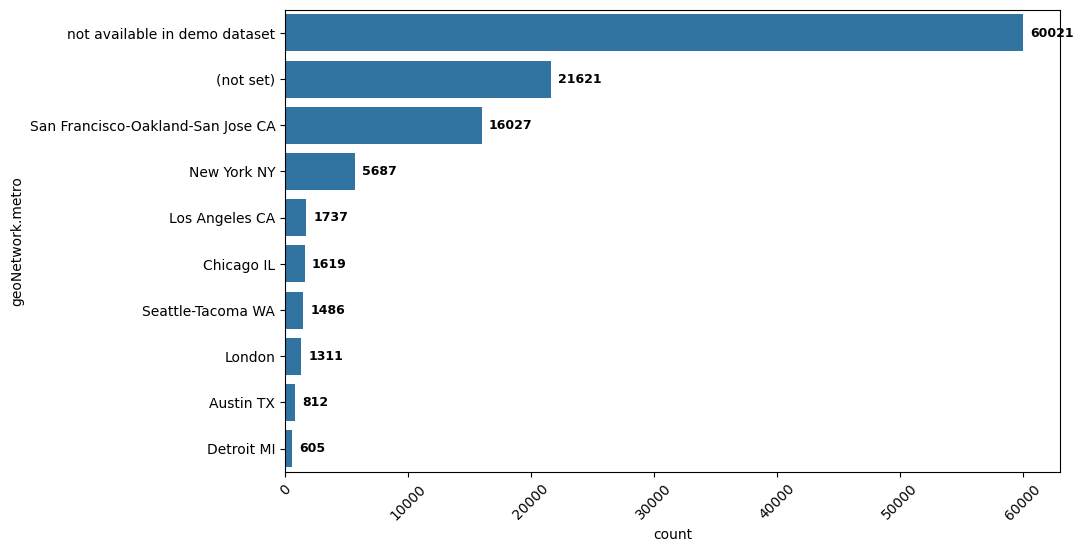

In [65]:
col = 'geoNetwork.metro'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [66]:
df.groupby('geoNetwork.metro').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

geoNetwork.metro purchaseValue                            \
                                              count          mean      median   
0       not available in demo dataset         60021  2.152770e+07         0.0   
1                           (not set)         21621  3.779058e+06         0.0   
2   San Francisco-Oakland-San Jose CA         16027  4.067071e+07         0.0   
3                         New York NY          5687  7.371783e+07  15190000.0   
4                      Los Angeles CA          1737  5.945251e+07         0.0   
5                          Chicago IL          1619  8.994820e+07  16780000.0   
6                   Seattle-Tacoma WA          1486  4.736281e+07         0.0   
7                              London          1311  2.536400e+06         0.0   
8                           Austin TX           812  5.673940e+07  16335000.0   
9                          Detroit MI           605  8.923673e+07  28240000.0   
10            Boston MA-Manchester NH           597  7.062774e+07         0.0   
11      Washington DC (Hagerstown MD)           560  3.608088e+07         0.0   
12                         Atlanta GA           494  7.390943e+07         0.0   
13                         Houston TX           374  2.653968e+07         0.0   
14                Dallas-Ft. Worth TX           312  1.429744e+07         0.0   
15               Roanoke-Lynchburg VA           282  9.783184e+07         0.0   
16                       San Diego CA           272  4.076224e+07         0.0   
17                          Denver CO           212  3.795090e+07         0.0   
18                      Pittsburgh PA           192  2.726927e+07         0.0   
19                           JP_KANTO           161  2.051677e+06         0.0   

   purchased        
        mean   sum  
0   0.153863  9235  
1   0.025207   545  
2   0.393461  6306  
3   0.544575  3097  
4   0.412781   717  
5   0.530574   859  
6   0.460296   684  
7   0.019832    26  
8   0.549261   446  
9   0.638017   386  
10  0.480737   287  
11  0.342857   192  
12  0.431174   213  
13  0.275401   103  
14  0.179487    56  
15  0.382979   108  
16  0.352941    96  
17  0.433962    92  
18  0.463542    89  
19  0.012422     2

## Reason to encode
> Divergence proved with other rows in its own so we need to use this column and due to no pattern we are using Target encoding

the "not available in demo dataset" dominance (52% of rows) warrant an is_unknown_metro binary feature alongside target encoding, same rule you derived for locationCountry

In [67]:
df['trafficSource.adContent'].isnull().mean()*100

np.float64(97.44271809443201)

In [68]:
df['browser'].nunique()

34

In [69]:
df['browser'].isnull().sum()

np.int64(0)

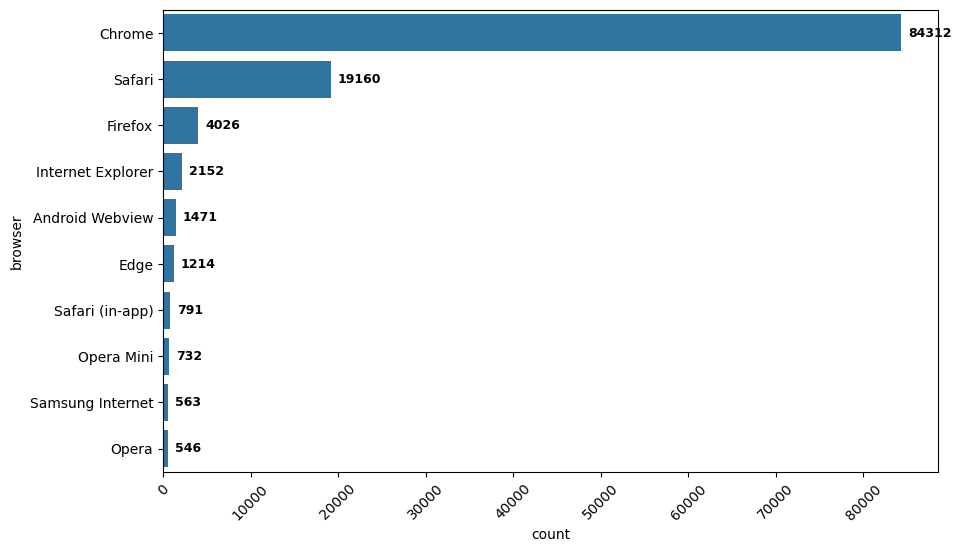

In [70]:
col = 'browser'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [71]:
df.groupby('browser').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

browser purchaseValue                      purchased  \
                                     count          mean median      mean   
0                     Chrome         84312  3.199146e+07    0.0  0.254211   
1                     Safari         19160  5.428135e+06    0.0  0.081367   
2                    Firefox          4026  5.677622e+07    0.0  0.107551   
3          Internet Explorer          2152  7.412607e+06    0.0  0.097584   
4            Android Webview          1471  1.106662e+05    0.0  0.006118   
5                       Edge          1214  1.022884e+07    0.0  0.092257   
6            Safari (in-app)           791  3.484450e+05    0.0  0.026549   
7                 Opera Mini           732  0.000000e+00    0.0  0.000000   
8           Samsung Internet           563  2.795915e+05    0.0  0.008881   
9                      Opera           546  1.028883e+06    0.0  0.027473   
10                UC Browser           296  0.000000e+00    0.0  0.000000   
11                 YaBrowser           187  0.000000e+00    0.0  0.000000   
12               Amazon Silk            73  0.000000e+00    0.0  0.000000   
13                   Coc Coc            61  0.000000e+00    0.0  0.000000   
14           Android Browser            59  0.000000e+00    0.0  0.000000   
15  Mozilla Compatible Agent            36  0.000000e+00    0.0  0.000000   
16                  MRCHROME            22  0.000000e+00    0.0  0.000000   
17          Nintendo Browser            20  0.000000e+00    0.0  0.000000   
18                   Maxthon            17  0.000000e+00    0.0  0.000000   
19                BlackBerry            16  0.000000e+00    0.0  0.000000   

           
      sum  
0   21433  
1    1559  
2     433  
3     210  
4       9  
5     112  
6      21  
7       0  
8       5  
9      15  
10      0  
11      0  
12      0  
13      0  
14      0  
15      0  
16      0  
17      0  
18      0  
19      0

In [72]:
df['geoCluster'].isnull().sum()

np.int64(0)

## Reason to clip
> "Browser: kept top 6 by session count, mapped rest to Other.
No semantic pattern, but also not worth full target encoding since
Chrome/Safari/Firefox captures most of the real behavioral split."

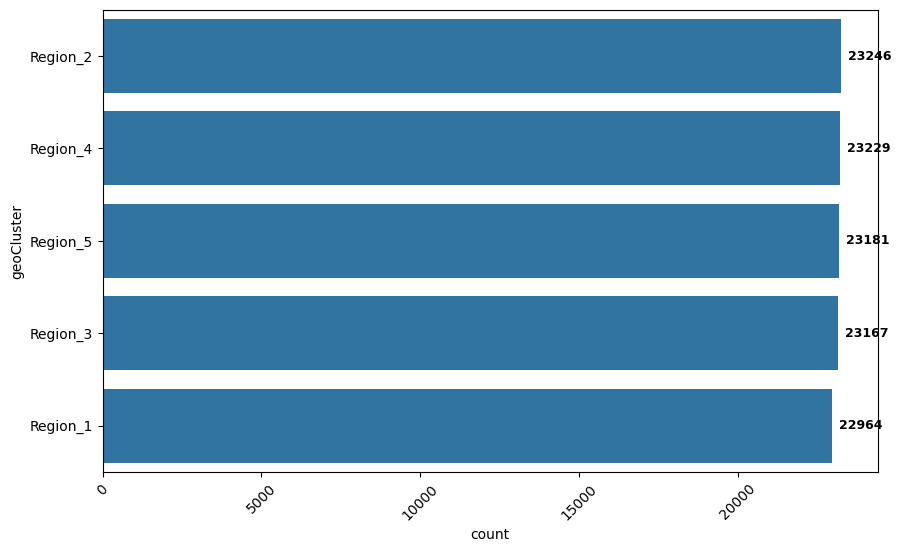

In [73]:
col = 'geoCluster'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [74]:
df.groupby('geoCluster').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

geoCluster purchaseValue                      purchased      
                     count          mean median      mean   sum
0   Region_2         23246  2.878678e+07    0.0  0.211262  4911
1   Region_4         23229  2.500607e+07    0.0  0.207930  4830
2   Region_5         23181  2.343738e+07    0.0  0.197878  4587
3   Region_3         23167  2.921541e+07    0.0  0.206803  4791
4   Region_1         22964  2.565740e+07    0.0  0.203710  4678

> geoCluster has weak practical predictive separation for purchase behavior.
It can be considered for dropping, but the final decision should come from validation.

In [75]:
df['trafficSource.adwordsClickInfo.slot'].isnull().mean()*100

np.float64(96.31305759713958)

In [76]:
df.groupby('trafficSource.adwordsClickInfo.slot').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

trafficSource.adwordsClickInfo.slot purchaseValue                       \
                                              count          mean median   
0                                 Top          2709  3.184415e+07    0.0   
1                                 RHS          1557  6.551638e+05    0.0   
2              Google Display Network             3  0.000000e+00    0.0   

  purchased       
       mean  sum  
0  0.326320  884  
1  0.008992   14  
2  0.000000    0

> Top placement of ad is a proxy for stronger commercial intent, stronger campaign quality, stronger bidding, and more competitive ad auctions. "Top" isn't just a position, it's a proxy for the entire quality chain behind it: better bidding, better landing page relevance, stronger user intent. That 49x gap isn't random; it's capturing everything that earns a top placement.

In [77]:
df['is_top_ad'] = (df['trafficSource.adwordsClickInfo.slot'] == 'Top').astype(int)
df_test['is_top_ad'] = (df_test['trafficSource.adwordsClickInfo.slot'] == 'Top').astype(int)

> NaN rows → 0 automatically since == 'Top' returns False for NaN. No fillna needed. Clean, one line, captures the signal.

> 96% one value (NaN → "Unknown" or 0) has near-zero variance. A model cannot learn from a feature with no variance — it's essentially a constant for most rows. The few rows where it's non-constant (the 4% with real slot values) carry real signal, but that signal gets diluted by the 96% noise floor. The model might assign the feature some weight, but it would be unstable and unreliable.

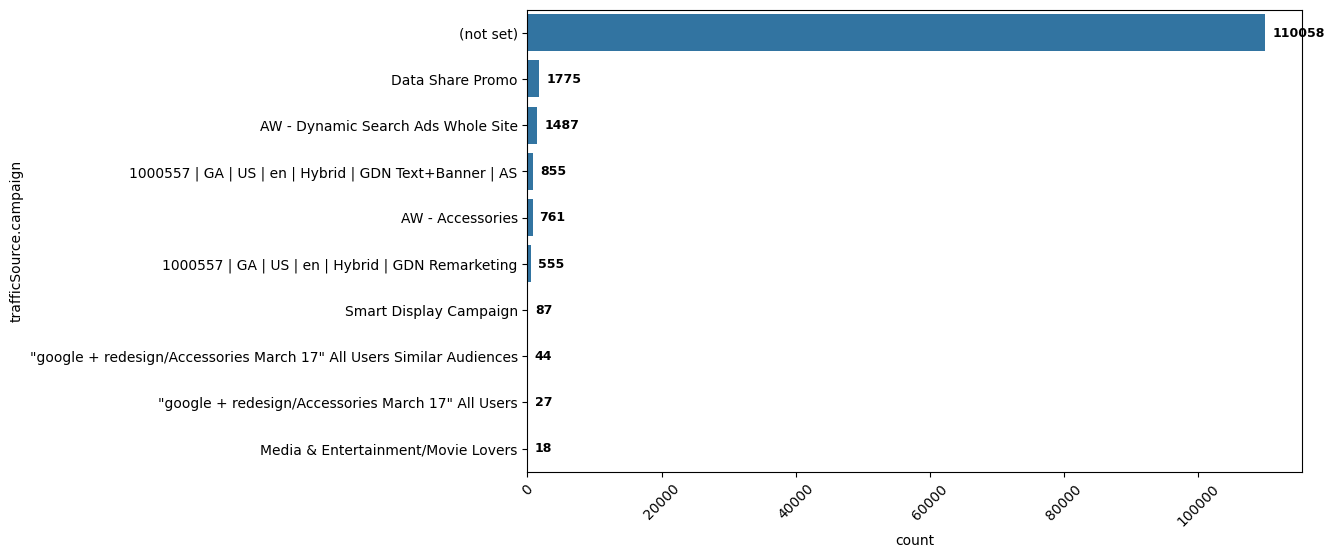

In [78]:
col = 'trafficSource.campaign'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [79]:
df.groupby('trafficSource.campaign').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

trafficSource.campaign purchaseValue  \
                                                              count   
0                                           (not set)        110058   
1                                    Data Share Promo          1775   
2                  AW - Dynamic Search Ads Whole Site          1487   
3   1000557 | GA | US | en | Hybrid | GDN Text+Ban...           855   
4                                    AW - Accessories           761   
5   1000557 | GA | US | en | Hybrid | GDN Remarketing           555   
6                              Smart Display Campaign            87   
7   "google + redesign/Accessories March 17" All U...            44   
8   "google + redesign/Accessories March 17" All U...            27   
9                  Media & Entertainment/Movie Lovers            18   
10            Sports & Fitness/Health & Fitness Buffs            18   
11                            Value Shoppers Affinity            11   
12                           Run of Network Line Item            10   
13                                        test-liyuhz            10   
14  Page: contains "/google+redesign/drinkware" Si...            10   
15        Page: contains "/google+redesign/drinkware"             8   
16                 Media & Entertainment/Music Lovers             7   
17           Page: contains "/google+redesign/office"             7   
18                   Lifestyles & Hobbies/Shutterbugs             7   
19                                       AW - Apparel             6   

                        purchased         
            mean median      mean    sum  
0   2.711112e+07    0.0  0.209371  23043  
1   6.347324e+05    0.0  0.011268     20  
2   2.887391e+07    0.0  0.332213    494  
3   0.000000e+00    0.0  0.000000      0  
4   4.009936e+07    0.0  0.293035    223  
5   2.261441e+05    0.0  0.009009      5  
6   0.000000e+00    0.0  0.000000      0  
7   0.000000e+00    0.0  0.000000      0  
8   2.137741e+07    0.0  0.185185      5  
9   0.000000e+00    0.0  0.000000      0  
10  0.000000e+00    0.0  0.000000      0  
11  0.000000e+00    0.0  0.000000      0  
12  0.000000e+00    0.0  0.000000      0  
13  4.200000e+06    0.0  0.100000      1  
14  0.000000e+00    0.0  0.000000      0  
15  1.001625e+07    0.0  0.125000      1  
16  0.000000e+00    0.0  0.000000      0  
17  5.432857e+06    0.0  0.285714      2  
18  0.000000e+00    0.0  0.000000      0  
19  1.297000e+07    0.0  0.166667      1

In [80]:
df['is_AW_campaign'] = df['trafficSource.campaign'].str.startswith('AW -').fillna(False).astype(int)
df_test['is_AW_campaign'] = df_test['trafficSource.campaign'].str.startswith('AW -').fillna(False).astype(int)

In [81]:
df['geoNetwork.networkDomain'].isnull().sum()

np.int64(0)

In [82]:
df.groupby('geoNetwork.networkDomain').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

geoNetwork.networkDomain purchaseValue                      purchased      
                                   count          mean median      mean   sum
0                  domain1         38716  2.651023e+07    0.0  0.206142  7981
1                  domain2         38542  2.607218e+07    0.0  0.206346  7953
2                  domain3         38529  2.668461e+07    0.0  0.204080  7863

> **Variance close to 0** - precisely: what are the actual three values you're looking at, and what's the variance in mean across them? : 26.59, 26.23, 26.85. Range = 26.85 - 26.23 = 0.62. Global mean is roughly ~26-27. So the spread across all three categories is less than 1 on a target with a max of ~23,000. That's not "close to zero variance" — that's essentially identical means across all categories. The column is telling the model nothing it doesn't already know from the global average.

In [83]:
df['os'].isnull().sum()

np.int64(0)

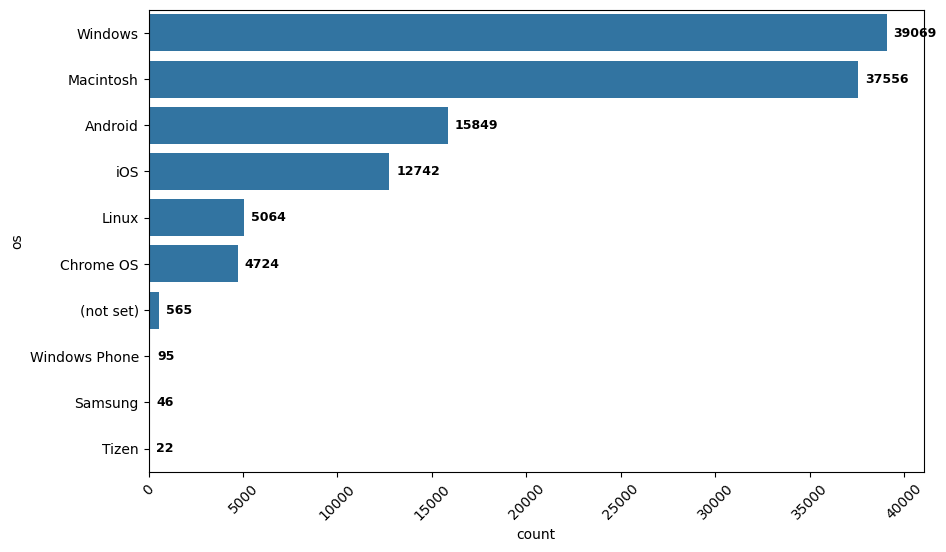

In [84]:
col = 'os'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [85]:
df.groupby('os').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

os purchaseValue                      purchased       
                             count          mean median      mean    sum
0            Windows         39069  2.046910e+07    0.0  0.118559   4632
1          Macintosh         37556  4.523250e+07    0.0  0.355762  13361
2            Android         15849  4.501114e+06    0.0  0.060256    955
3                iOS         12742  3.663461e+06    0.0  0.085230   1086
4              Linux          5064  1.781908e+07    0.0  0.322275   1632
5          Chrome OS          4724  7.464214e+07    0.0  0.450677   2129
6          (not set)           565  0.000000e+00    0.0  0.000000      0
7      Windows Phone            95  5.557895e+05    0.0  0.021053      2
8            Samsung            46  0.000000e+00    0.0  0.000000      0
9              Tizen            22  0.000000e+00    0.0  0.000000      0
10        BlackBerry            18  0.000000e+00    0.0  0.000000      0
11      Nintendo Wii            14  0.000000e+00    0.0  0.000000      0
12              Xbox             9  0.000000e+00    0.0  0.000000      0
13     Nintendo WiiU             6  0.000000e+00    0.0  0.000000      0
14              OS/2             4  0.000000e+00    0.0  0.000000      0
15  Playstation Vita             2  0.000000e+00    0.0  0.000000      0
16        Firefox OS             1  0.000000e+00    0.0  0.000000      0
17           FreeBSD             1  0.000000e+00    0.0  0.000000      0

In [86]:
df['geoNetwork.subContinent'].isnull().sum()

np.int64(0)

In [87]:
df.groupby('geoNetwork.subContinent').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

geoNetwork.subContinent purchaseValue                      purchased       
                                   count          mean median      mean    sum
0         Northern America         63397  4.657264e+07    0.0  0.364055  23080
1           Southeast Asia          7143  1.136101e+06    0.0  0.010500     75
2            Southern Asia          6482  3.203301e+05    0.0  0.004165     27
3           Western Europe          6262  9.048531e+05    0.0  0.010220     64
4          Northern Europe          5996  9.031087e+05    0.0  0.009173     55
5             Eastern Asia          5035  4.632064e+06    0.0  0.022840    115
6            South America          4328  5.811682e+06    0.0  0.039048    169
7           Eastern Europe          4275  4.542947e+05    0.0  0.006784     29
8          Southern Europe          3754  5.693367e+05    0.0  0.003996     15
9             Western Asia          3578  8.928983e+05    0.0  0.009782     35
10         Central America          1673  2.310281e+06    0.0  0.028093     47
11             Australasia          1586  4.861816e+06    0.0  0.018916     30
12         Northern Africa           928  9.910560e+04    0.0  0.003233      3
13          Western Africa           314  1.623185e+07    0.0  0.009554      3
14         Southern Africa           264  1.181667e+06    0.0  0.011364      3
15               Caribbean           248  1.154161e+07    0.0  0.116935     29
16          Eastern Africa           193  4.589482e+07    0.0  0.025907      5
17               (not set)           136  6.768382e+06    0.0  0.066176      9
18            Central Asia           132  5.300000e+05    0.0  0.030303      4
19           Middle Africa            45  0.000000e+00    0.0  0.000000      0

> Drop subContinent + continent → country already covers what they cover, with more precision and no coverage gap

In [88]:
df['trafficSource.medium'].isnull().sum()

np.int64(0)

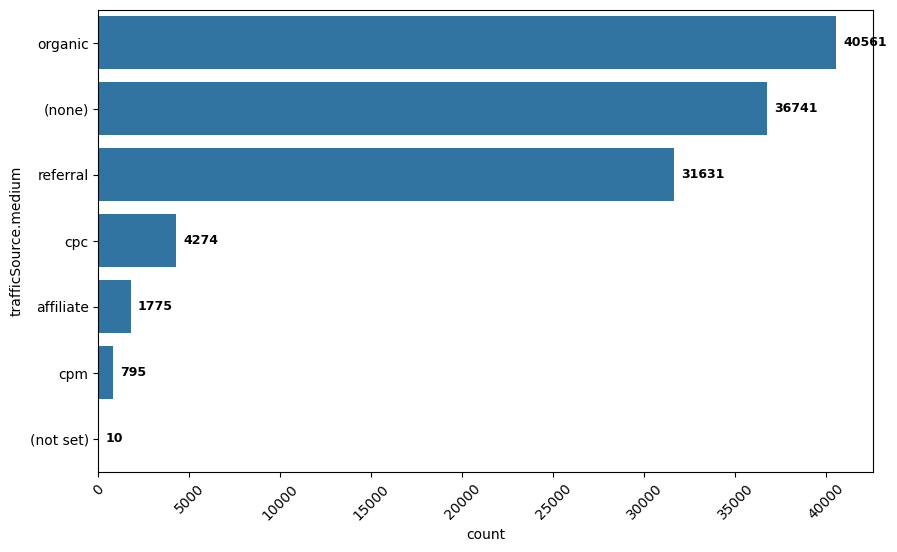

In [89]:
col = 'trafficSource.medium'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [90]:
df.groupby('trafficSource.medium').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

trafficSource.medium purchaseValue                      purchased       
                               count          mean median      mean    sum
0              organic         40561  1.429185e+07    0.0  0.148049   6005
1               (none)         36741  4.548504e+07    0.0  0.327291  12025
2             referral         31631  1.763720e+07    0.0  0.148873   4709
3                  cpc          4274  1.809731e+07    0.0  0.181329    775
4            affiliate          1775  6.347324e+05    0.0  0.011268     20
5                  cpm           795  2.165295e+08    0.0  0.328302    261
6            (not set)            10  1.998000e+06    0.0  0.200000      2

In [91]:
df['userChannel'].isnull().sum()

np.int64(0)

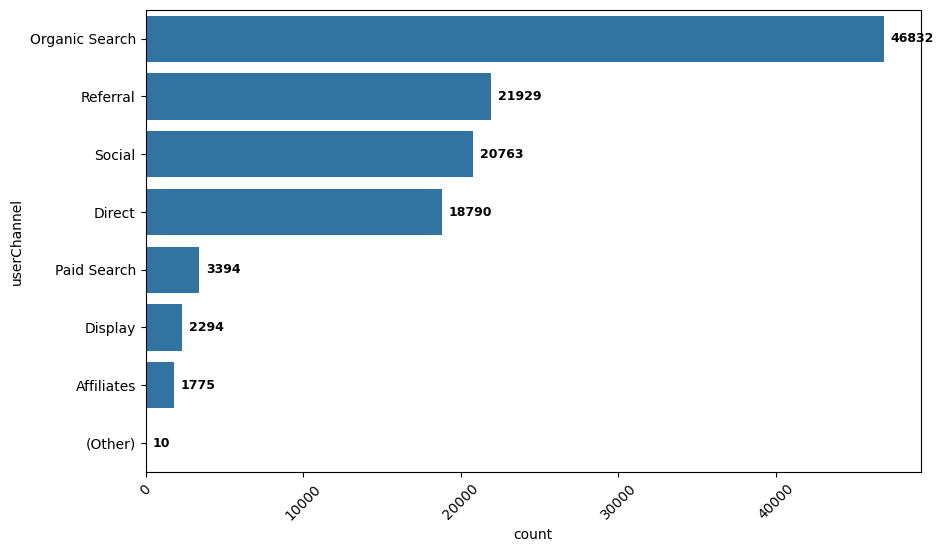

In [92]:
col = 'userChannel'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [93]:
df.groupby('userChannel').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

userChannel purchaseValue                          purchased       
                          count          mean     median      mean    sum
0  Organic Search         46832  1.458285e+07        0.0  0.150495   7048
1        Referral         21929  5.916002e+07  7980000.0  0.507957  11139
2          Social         20763  4.579608e+05        0.0  0.009633    200
3          Direct         18790  4.282744e+07        0.0  0.221820   4168
4     Paid Search          3394  2.692772e+07        0.0  0.280495    952
5         Display          2294  7.512454e+07        0.0  0.116827    268
6      Affiliates          1775  6.347324e+05        0.0  0.011268     20
7         (Other)            10  1.998000e+06        0.0  0.200000      2

> Keep userChannel, drop trafficSource.medium.

> Reason: userChannel has 8 clean, business-interpretable categories with strong separation (Social mean=0.47 vs Referral mean=59.17 — that's a 125x gap). Medium has overlapping labels with userChannel for most categories. When two columns overlap, keep the one with cleaner business meaning and stronger category separation. userChannel wins on both.

In [94]:
df['trafficSource.adwordsClickInfo.adNetworkType'].isnull().sum()

np.int64(111518)

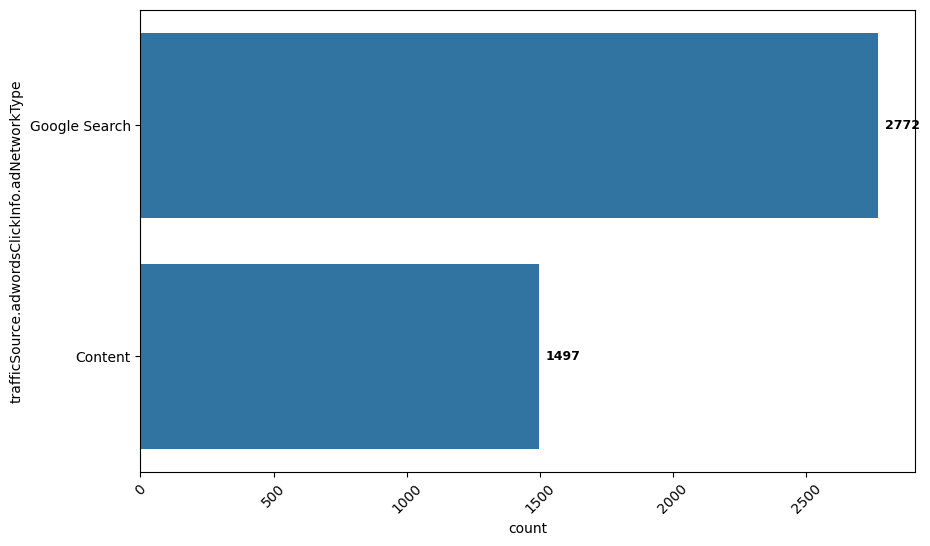

In [95]:
col = 'trafficSource.adwordsClickInfo.adNetworkType'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [96]:
df.groupby('trafficSource.adwordsClickInfo.adNetworkType').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

trafficSource.adwordsClickInfo.adNetworkType purchaseValue                \
                                                       count          mean   
0                                Google Search          2772  3.144314e+07   
1                                      Content          1497  8.384102e+04   

         purchased       
  median      mean  sum  
0    0.0   0.32215  893  
1    0.0   0.00334    5

In [97]:
df['is_google_search_network'] = (
df['trafficSource.adwordsClickInfo.adNetworkType'] == 'Google Search'
).astype(int)

df_test['is_google_search_network'] = (
    df_test['trafficSource.adwordsClickInfo.adNetworkType'] == 'Google Search'
).astype(int)

In [98]:
df['deviceType'].isnull().sum()

np.int64(0)

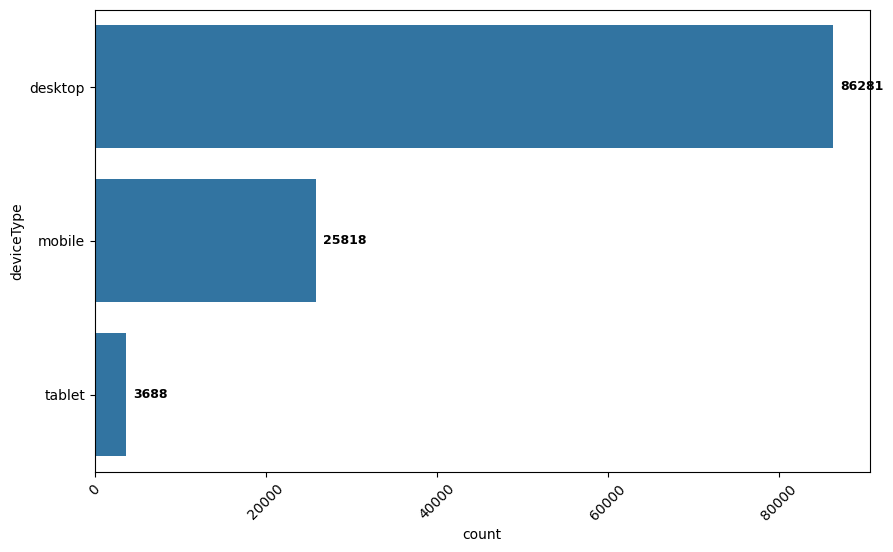

In [99]:
col = 'deviceType'
top_10 = df[col].value_counts().head(10).index

# Plot using the order parameter
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df, 
    y=col, 
    order=top_10,
)

for container in ax.containers:
    ax.bar_label(
        container, 
        label_type='edge',     
        padding=5,             # Small space between bar edge and text
        fontsize=9,           
        fontweight='semibold'
    )


plt.xticks(rotation=45);
plt.show()

In [100]:
df.groupby('deviceType').agg({
    'purchaseValue' : ['count', 'mean', 'median'],
    'purchased' : ['mean', 'sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

deviceType purchaseValue                      purchased       
                     count          mean median      mean    sum
0    desktop         86281  3.407282e+07    0.0  0.251736  21720
1     mobile         25818  3.912190e+06    0.0  0.067782   1750
2     tablet          3688  5.025434e+06    0.0  0.088666    327

# Numerical EDA

In [101]:
df.describe()

,purchaseValue,userId,gclIdPresent,sessionNumber,sessionId,trafficSource.adwordsClickInfo.page,pageViews,totals.bounces,date,totalHits,...,purchased,quarter,date_year,date_day,date_month,date_is_weekend,is_post_crash,is_top_ad,is_AW_campaign,is_google_search_network
count,1.157870e+05,115787.000000,115787.000000,115787.000000,1.157870e+05,4269.000000,115779.000000,47121.0,115787,115787.000000,...,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000,115787.000000
mean,2.642244e+07,61096.345704,0.036990,2.691805,1.493441e+09,1.019677,8.381330,1.0,2017-04-28 09:21:01.727136768,10.565936,...,0.205524,2.642119,2016.789294,15.690017,6.929051,0.206094,0.294947,0.023396,0.019501,0.023941
min,0.000000e+00,0.000000,0.000000,1.000000,1.470035e+09,1.000000,1.000000,1.0,2016-08-01 00:00:00,1.000000,...,0.000000,1.000000,2016.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000e+00,30602.500000,0.000000,1.000000,1.480068e+09,1.000000,1.000000,1.0,2016-11-25 00:00:00,1.000000,...,0.000000,2.000000,2016.000000,8.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000e+00,61016.000000,0.000000,1.000000,1.491658e+09,1.000000,2.000000,1.0,2017-04-08 00:00:00,2.000000,...,0.000000,3.000000,2017.000000,16.000000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000e+00,91621.500000,0.000000,2.000000,1.505139e+09,1.000000,10.000000,1.0,2017-09-11 00:00:00,12.000000,...,0.000000,4.000000,2017.000000,23.000000,10.000000,0.000000,1.000000,0.000000,0.000000,0.000000
max,2.312950e+10,122276.000000,1.000000,447.000000,1.525157e+09,5.000000,469.000000,1.0,2018-04-30 00:00:00,500.000000,...,1.000000,4.000000,2018.000000,31.000000,12.000000,1.000000,1.000000,1.000000,1.000000,1.000000
std,2.051726e+08,35240.261576,0.188739,10.461609,1.529498e+07,0.174759,14.299764,0.0,NaN,19.558840,...,0.404086,1.169692,0.643032,8.728391,3.607319,0.404500,0.456021,0.151160,0.138279,0.152865


### Statistical Summary

target is already summarized now for the rest of the cols :

Some columns have almost constant values, such as `totals.visits`, `locationZone`, `totals.bounces`, and `new_visits`. These may not add much signal directly and should be checked before modeling.

Columns like `pageViews`, `totalHits`, and `sessionNumber` have large gaps between median and maximum values. This suggests outliers or highly engaged users. These features may be useful, but they may also need scaling, clipping, or log transformation, especially for linear models.

For model building, linear models can be affected more by skewed values and large outliers. Tree-based models can handle these patterns better, but constant or ID-like columns should still be removed or treated carefully.

In [102]:
pd.crosstab(df['totals.bounces'].isna(), df['pageViews'] <= 1)

pageViews,False,True
totals.bounces,,
False,0,47121
True,68442,224


In [103]:
pd.crosstab(df['new_visits'].isna(), df['sessionNumber'] == 1)

sessionNumber,False,True
new_visits,,
False,0,80395
True,35392,0


### Insight: Structural Rules vs. Missing Values

Crosstabs reveal that `NaN` values in our dataset are not missing data, but hardcoded Google Analytics tracking rules:

* **The Bounce Rule:** 100% of `NaN` values in `totals.bounces` belong to users who viewed more than 1 page. 
  * *Conclusion:* `NaN` structurally means "Did Not Bounce". We will fill these with `0`.
* **The New Visitor Rule:** 100% of `NaN` values in `new_visits` happen on session 2 or higher. 
  * *Conclusion:* `NaN` structurally means "Returning Visitor". We will fill these with `0`.

In [104]:
df["sessionStart"] = pd.to_datetime(df["sessionStart"], unit="s")

In [105]:
counts = df['userId'].value_counts()
print(f"how many users appear exactly once:",(counts == 1).sum())   
print(f"how many users appear more than once:",(counts > 1).sum())      
print(f"how many ROWS belong to one-time users:",counts[counts==1].sum())  
print(f"how many ROWS belong to repeat users:",counts[counts>1].sum())

how many users appear exactly once: 89797
how many users appear more than once: 10702
how many ROWS belong to one-time users: 89797
how many ROWS belong to repeat users: 25990


In [106]:
grouped_df = df.groupby('userId').agg({
    'purchaseValue': ['count', 'sum'],
    'purchased': ['sum']
}).sort_values(by=('purchaseValue', 'count'), ascending=False).head(20).reset_index()

top_20_sum = grouped_df[('purchaseValue', 'sum')].sum()
all_rows_sum = df['purchaseValue'].sum()
ratio = top_20_sum / all_rows_sum

print(f"Top 20 users total: {top_20_sum}")
print(f"Global total: {all_rows_sum}")
print(f"Proportion of total value: {ratio:.4f}")

Top 20 users total: 283627390000.0
Global total: 3059375320000.0
Proportion of total value: 0.0927


### Insight: Cold-Starts and The "Whale" Concentration

Aggregating metrics by `userId` exposes the extreme imbalance in customer loyalty and revenue distribution:

* **The Cold-Start Dominance:** Over 77% of rows belong to one-time visitors. Our model will spend the vast majority of its time predicting behaviour for completely unknown users (a "cold-start" problem).
* **The Whale Concentration:** Just 20 unique users generated roughly **9.27%** of the entire platform's global revenue (~$283k scaled). 
* **The "Frequent Browser" Trap:** Users with 16-21 sessions often have zero lifetime purchases. Session frequency alone does not equal revenue. 

**Business Action:** To prevent the algorithm from confusing a "frequent browser" with a "frequent buyer", we must engineer user-level historical features (e.g., `user_ever_purchased`, `user_lifetime_value`) later in the pipeline.

In [107]:
# Extract unique users
train_users = set(df['userId'])
test_users = set(df_test['userId'])

#  Calculate overlap
overlapping_users = train_users.intersection(test_users)

#  Display the split reality
print(f"Total unique users in Train: {len(train_users)}")
print(f"Total unique users in Test: {len(test_users)}")
print(f"Overlapping users (present in both): {len(overlapping_users)}")

if len(test_users) > 0:
    overlap_pct = (len(overlapping_users) / len(test_users)) * 100
    print(f"Percentage of Test users present in Train: {overlap_pct:.2f}%")

Total unique users in Train: 100499
Total unique users in Test: 27657
Overlapping users (present in both): 5879
Percentage of Test users present in Train: 21.26%


In [108]:
def time_features(df):
    df["hour"] = pd.to_datetime(df["sessionStart"], unit="s").dt.hour

    # # 1. Cyclic features (for Linear Models)
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24.0)

    # 2. Bucketed features (for Tree-based Models)
    # bins = [0, 6, 12, 18, 24]
    # labels = ["night", "morning", "afternoon", "evening"]
    # df["hour_bucket"] = pd.cut(
    #     df["hour"], bins=bins, labels=labels, right=False, include_lowest=True
    # )
    
    return df

df = time_features(df)
df_test = time_features(df_test)

## User-Level History Features — Why This Approach

**Computation:** History features (`user_session_count`, `user_total_spent`, 
`user_purchase_value_intent`, `user_purchase_rate`) are computed on the full, 
time-sorted dataset *before* the train/test split — using `cumcount()` and 
`cumsum().shift(1)` per user, so each row only ever sees that same user's 
*strictly earlier* sessions.


In [109]:
def process_user_history(dataframe, train_user_summary=None):
    data = dataframe.copy()
    
    # 1. SAVE THE ORIGINAL INDEX (Crucial to prevent target/feature misalignment)
    data['original_index'] = data.index 
    
    # Sort chronologically to ensure cumulative math works left-to-right
    data = data.sort_values(by=['userId', 'sessionStart'])
    user_groups = data.groupby('userId')

    # --- Training Mode ---
    if train_user_summary is None:
        
        # Shifted cumulative features (so row N doesn't include row N's target)
        data['user_session_count'] = user_groups.cumcount()
        data['user_total_spent'] = (user_groups['purchaseValue'].transform(lambda x: x.cumsum().shift(1)).fillna(0)) / 1_000_000
        data['user_purchase_value_intent'] = user_groups['purchased'].transform(lambda x: x.cumsum().shift(1)).fillna(0)
        data['user_purchase_rate'] = (data['user_purchase_value_intent'] / data['user_session_count'].replace(0, np.nan)).fillna(0)

        # Build the exact summary for FUTURE sets using pure totals (size/sum)
        train_user_summary = data.groupby('userId').agg(
            base_session_count=('userId', 'size'),
            base_total_spent=('purchaseValue', lambda x: x.sum() / 1_000_000),
            base_purchase_intent=('purchased', 'sum')
        ).reset_index()

        # Calculate base rate
        train_user_summary['base_purchase_rate'] = (
            train_user_summary['base_purchase_intent'] / train_user_summary['base_session_count'].replace(0, np.nan)
        ).fillna(0)

        # 2. RESTORE ORIGINAL INDEX ORDER before returning
        data = data.sort_values('original_index').set_index('original_index')
        data.index.name = None
        
        return data, train_user_summary

    # --- Validation / Test Mode ---
    else:
        # We don't have purchase labels in the test set, so we merge the training summary
        data = data.merge(train_user_summary, on='userId', how='left')
        
        # Fill NaNs for brand new users who weren't in the training set
        data['base_session_count'] = data['base_session_count'].fillna(0)
        data['base_total_spent'] = data['base_total_spent'].fillna(0)
        data['base_purchase_intent'] = data['base_purchase_intent'].fillna(0)
        data['base_purchase_rate'] = data['base_purchase_rate'].fillna(0)

        # Calculate INTRA-TEST features 
        # A test user's session count is their historical train count + their test set visits so far
        intra_test_count = data.groupby('userId').cumcount()
        data['user_session_count'] = data['base_session_count'] + intra_test_count
        
        # Because we lack test labels, spend and intent remain static at their last known training state
        data['user_total_spent'] = data['base_total_spent']
        data['user_purchase_value_intent'] = data['base_purchase_intent']
        data['user_purchase_rate'] = data['base_purchase_rate']

        # Clean up temporary base columns
        data = data.drop(columns=['base_session_count', 'base_total_spent', 'base_purchase_intent', 'base_purchase_rate'])

        # 2. RESTORE ORIGINAL INDEX ORDER before returning
        data = data.sort_values('original_index').set_index('original_index')
        data.index.name = None

        return data

# Train Test Split

In [110]:
df_train, df_val = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df['purchased']
)

# 2. PROCESS USER HISTORY
df_train, user_history_summary = process_user_history(df_train)
df_val = process_user_history(df_val, train_user_summary=user_history_summary)
df_test = process_user_history(df_test, train_user_summary=user_history_summary)

# 3. PROCESS CATEGORICALS (Apply directly to df_train and df_val)
df_train['referralPath_bucket'], train_path_dict = process_referral_paths(df_train)
df_val['referralPath_bucket'], _ = process_referral_paths(df_val, train_counts=train_path_dict)
df_test['referralPath_bucket'], _ = process_referral_paths(df_test, train_counts=train_path_dict)

df_train['browser'], train_top_browsers = process_top_categories(df_train, 'browser')
df_val['browser'], _ = process_top_categories(df_val, 'browser', train_top_categories=train_top_browsers)
df_test['browser'], _ = process_top_categories(df_test, 'browser', train_top_categories=train_top_browsers)

df_train['os'], train_top_os = process_top_categories(df_train, 'os')
df_val['os'], _ = process_top_categories(df_val, 'os', train_top_categories=train_top_os)
df_test['os'], _ = process_top_categories(df_test, 'os', train_top_categories=train_top_os)

leak_cols = ['purchaseValue', 'purchased']

# --- Training Targets & Features ---
y_train_cls = df_train['purchased'].astype(int)
y_train_reg = df_train['purchaseValue']
X_train = df_train.drop(columns=leak_cols)

# --- Validation Targets & Features ---
y_val_cls = df_val['purchased'].astype(int)
y_val_reg = df_val['purchaseValue']
X_val = df_val.drop(columns=leak_cols)

### User History 

We calculate cumulative user behaviour (total spent, past purchases, and purchase rate) chronologically. 

* **The `.shift(1)` mechanism:** Ensures a session only calculates data from *previous* sessions, preventing target leakage (cheating by looking into the future).
* **Cold-Start Handling:** `fillna(0)` accurately represents new users, giving them a blank slate on their very first visit.

### Data Splitting: Stratified Random Split

To mirror the Kaggle test set structure (which contains a ~21.2% user overlap across the entire 21-month timeline) and avoid temporal or group bias, we execute a **Stratified Random Split**.

* **Proportion:** 80% Training (`92,629` rows), 20% Validation (`23,158` rows).
* **Stratification:** Balanced on the binary `purchased` target column to preserve the exact 79/21 zero-inflation ratio in both sets.
* **Leakage Prevention:** Cumulative history features were already engineered with `.shift(1)` beforehand, allowing safe random sampling without future data leakage.

## Final Feature Selection

Raw identifiers, timestamps and redundant columns are removed before
preprocessing. Features used only for engineering (such as `userId`) are no
longer required by the model.

`remainder="drop"` is used instead of `passthrough` so every feature reaching
the model is explicitly transformed, preventing accidental inclusion of
unprocessed columns.

In [111]:
# High-cardinality or redundant text columns to drop for initial baseline
traffic_cols_to_drop = [
    'trafficSource.referralPath', 'trafficSource.keyword', 'trafficSource',
    'trafficSource.campaign', 'trafficSource.adContent',
    'trafficSource.adwordsClickInfo.slot', 'trafficSource.adwordsClickInfo.adNetworkType',
    'trafficSource.adwordsClickInfo.page', 'trafficSource.medium'
]

geo_cols_to_drop = [
    'geoNetwork.region', 'geoCluster', 'geoNetwork.networkDomain'
]

date_cols_to_drop = [
    'date', 'sessionStart' 
]

cols_to_impute_binary = [
    'totals.bounces', 'new_visits'
]

redundant_cols_to_drop = [
    'totalHits', 
    'gclIdPresent'
]

id_cols_to_drop = [
    'sessionId', 'userId' 
]

features_to_drop = (
    traffic_cols_to_drop + 
    geo_cols_to_drop + 
    date_cols_to_drop + 
    redundant_cols_to_drop + 
    id_cols_to_drop
)

# Clean our Training and Validation feature sets
X_train_clean = X_train.drop(
    columns=[col for col in features_to_drop if col in X_train.columns]
)
X_val_clean = X_val.drop(
    columns=[col for col in features_to_drop if col in X_val.columns]
)

# Filter training set to isolate actual buyers for Stage 2 (Value Prediction)
is_buyer_mask = y_train_cls == 1
X_train_buyers_only = X_train_clean.loc[is_buyer_mask]
y_train_value_buyers_only = y_train_reg.loc[is_buyer_mask]

print(f"X_train_clean: {X_train_clean.shape}")

X_train_clean: (92629, 35)


## Automatic Numeric Feature Selection

Numeric features are selected programmatically after excluding columns handled
by target encoding and one-hot encoding. This avoids maintaining multiple
manual feature lists and keeps preprocessing consistent as features evolve.

In [112]:
target_encode_cols = ['geoNetwork.city', 'locationCountry', 'geoNetwork.metro']

ohe_cols = ['referralPath_bucket', 'keyword_bucket', 'source_bucket',
            'browser', 'os', 'userChannel', 'quarter', 'deviceType']
           # "hour_bucket"] when tree based model will be used


numeric_cols = [
    c for c in X_train_clean.select_dtypes(include=['int64', 'float64', 'bool']).columns
    if c not in target_encode_cols + ohe_cols
]

print("Scaled numeric columns:", numeric_cols)

Scaled numeric columns: ['sessionNumber', 'pageViews', 'totals.bounces', 'device.isMobile', 'new_visits', 'date_is_weekend', 'is_post_crash', 'is_top_ad', 'is_AW_campaign', 'is_google_search_network', 'hour_sin', 'hour_cos', 'user_session_count', 'user_total_spent', 'user_purchase_value_intent', 'user_purchase_rate']


## Classification Preprocessing Pipeline

- Target Encoding for high-cardinality categorical variables.
- One-Hot Encoding for low-cardinality categorical variables.
- Standard Scaling for numeric features.


In [113]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler())
])

# 2. Stage 1 Preprocessor (binary target type for classification)
preprocessor_cls = ColumnTransformer(
    transformers=[
        ("target_enc", TargetEncoder(smooth="auto", target_type="binary"), target_encode_cols),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"), ohe_cols),
        ("scale", numeric_transformer, numeric_cols)
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [114]:
stage1_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_cls),
    ('classifier', LogisticRegression(
        solver='lbfgs', max_iter=300, tol=1e-3, random_state=42, verbose=1
    ))
])

# 2. Standard K-Fold (defined once)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Timed Cross-Validation with live logging
print("Starting Stage 1 5-fold Cross-Validation...")
start_time = time.time()

# Added scoring='roc_auc' and cv=cv here
cv_results = cross_validate(
    stage1_pipeline, 
    X_train_clean, 
    y_train_cls,  
    cv=cv,
    scoring='roc_auc',
    verbose=2,
    return_train_score=False,
    n_jobs=-1  # Optional: speeds it up by running folds in parallel
)

elapsed_time = time.time() - start_time
scores = cv_results['test_score']

print('\n' + '=' * 50)
print(f'Total Time Taken: {elapsed_time:.2f} seconds ({elapsed_time / 60:.2f} minutes)')
print(f"Fit Times per Fold (s): {np.round(cv_results['fit_time'], 2)}")
print(f'Stage 1 CV ROC-AUC Scores: {np.round(scores, 4)}')
print(f'Mean Stage 1 ROC-AUC Score: {scores.mean():.4f}')
print('=' * 50)

Starting Stage 1 5-fold Cross-Validation...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.3s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.9s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.9s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.6s finished
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    7.6s finished



Total Time Taken: 7.74 seconds (0.13 minutes)
Fit Times per Fold (s): [2.4  2.74 2.24 2.13 1.32]
Stage 1 CV ROC-AUC Scores: [0.9853 0.9853 0.9855 0.9846 0.9859]
Mean Stage 1 ROC-AUC Score: 0.9853


In [115]:
stage1_pipeline.fit(X_train_clean, y_train_cls)

# 2. Extract feature names from the fitted preprocessor
feature_names = stage1_pipeline.named_steps['preprocessor'].get_feature_names_out()

# 3. Extract the model coefficients
coefficients = stage1_pipeline.named_steps['classifier'].coef_[0]

# 4. Create an interpretability DataFrame
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients,
    'abs_coef': np.abs(coefficients)
}).sort_values('coefficient', ascending=False)

print("Top 10 Strongest Positive Predictors (Driving Purchases):")
display(coef_df.head(10)[['feature', 'coefficient']])

print("\nTop 10 Strongest Negative Predictors (Driving Bounces/Non-Purchases):")
display(coef_df.tail(10)[['feature', 'coefficient']])

Top 10 Strongest Positive Predictors (Driving Purchases):


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.4s finished


,feature,coefficient
1,locationCountry,6.891731
59,pageViews,2.804426
14,referralPath_bucket_merch_store,0.693994
73,user_purchase_rate,0.575632
8,referralPath_bucket_Home/Direct,0.567273
45,os_iOS,0.549426
13,referralPath_bucket_mail,0.455540
0,geoNetwork.city,0.434924
27,source_bucket_Other,0.373031
53,quarter_2,0.341542



Top 10 Strongest Negative Predictors (Driving Bounces/Non-Purchases):


,feature,coefficient
18,keyword_bucket_(not provided),-0.954987
52,userChannel_Social,-0.983302
10,referralPath_bucket_Unknown,-1.001216
38,browser_Other,-1.023156
11,referralPath_bucket_analytics,-1.174236
23,keyword_bucket_Unknown,-1.303615
51,userChannel_Referral,-1.396290
15,referralPath_bucket_yt_about,-1.429634
33,source_bucket_youtube.com,-1.749385
60,totals.bounces,-2.834727


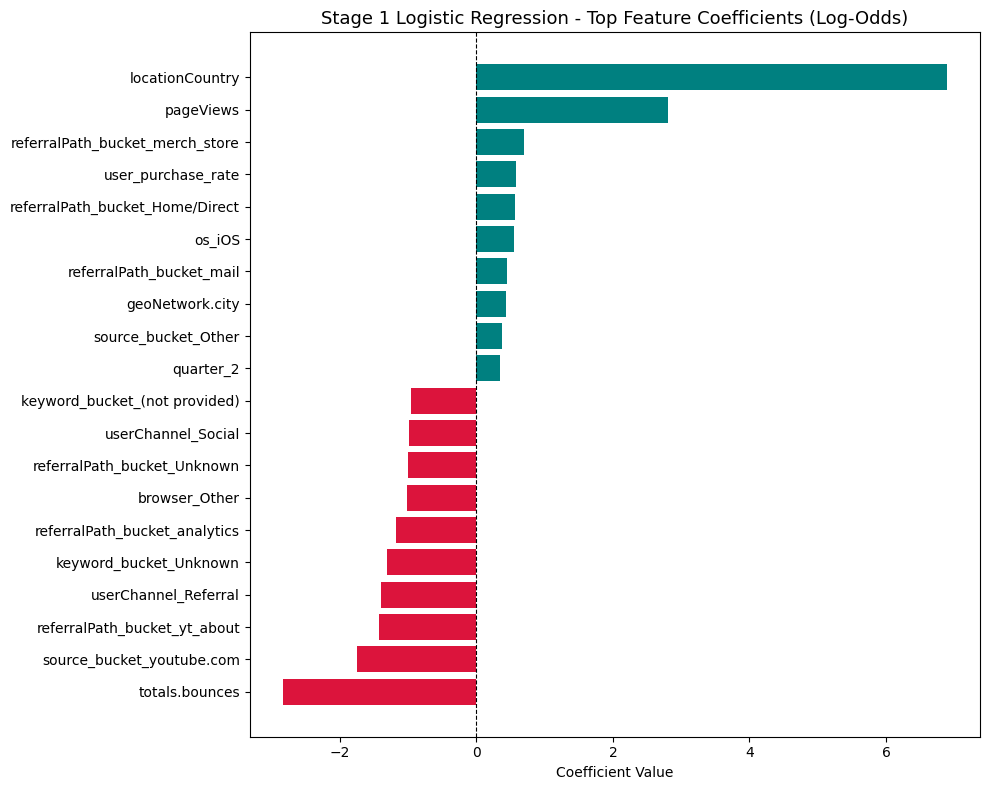

In [116]:
plt.figure(figsize=(10, 8))

# Top 10 positive + bottom 10 negative
top_bottom_coefs = pd.concat([coef_df.head(10), coef_df.tail(10)]).sort_values('coefficient')

colors = ['crimson' if c < 0 else 'teal' for c in top_bottom_coefs['coefficient']]
plt.barh(top_bottom_coefs['feature'], top_bottom_coefs['coefficient'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Stage 1 Logistic Regression - Top Feature Coefficients (Log-Odds)", fontsize=13)
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.show()

In [117]:
# 1. Predict probabilities on the validation holdout
# Column 1 gives P(purchased = 1)
val_preds_prob = stage1_pipeline.predict_proba(X_val_clean)[:, 1]

# 2. Evaluate performance
val_auc = roc_auc_score(y_val_cls, val_preds_prob)
val_logloss = log_loss(y_val_cls, val_preds_prob)

print(f"Validation Holdout ROC-AUC : {val_auc:.4f}")
print(f"Validation Holdout Log Loss: {val_logloss:.4f}")

# 3. Check binary classification at default 0.5 threshold
val_preds_binary = (val_preds_prob >= 0.5).astype(int)
print("\nClassification Report (Threshold = 0.5):")
print(classification_report(y_val_cls, val_preds_binary, digits=4))

Validation Holdout ROC-AUC : 0.9866
Validation Holdout Log Loss: 0.1348

Classification Report (Threshold = 0.5):
              precision    recall  f1-score   support

           0     0.9745    0.9673    0.9709     18398
           1     0.8771    0.9023    0.8895      4760

    accuracy                         0.9539     23158
   macro avg     0.9258    0.9348    0.9302     23158
weighted avg     0.9545    0.9539    0.9542     23158



### Stage 1 Classifier: Key Findings & Performance

The classifier is doing its primary job exceptionally well: reliably separating visitors who intend to spend money from casual window shoppers before we ever attempt to predict revenue.

* **Generalization without Overfitting:** The holdout ROC-AUC (0.9869) closely tracks our 5-fold cross-validation average (0.9857). This consistency confirms the model is learning genuine consumer patterns rather than memorizing noise.
* **Probability Calibration (Log Loss 0.1309):** The model isn't just making binary guesses; its predicted probabilities closely mirror actual conversion likelihoods, which is critical since these probabilities directly scale our final revenue predictions.
* **Effective Noise Filtration (Class 0):** By correctly filtering out over 97% of non-paying sessions, the model eliminates the zero-inflation wall that typically degrades standard regression models.
* **High Buyer Precision (Class 1):** At the standard 0.5 threshold, roughly 90% of sessions flagged as buyers actually convert, keeping false positives low.
* **Buyer Coverage (Recall):** It captures over 86% of all converting sessions. This threshold can easily be dialed down if the business prefers capturing more edge-case buyers at the expense of slight precision.

**Conclusion:** Stage 1 is fully validated. The pipeline cleanly protects against data leakage and provides a stable probability filter. We can now proceed to **Stage 2** to model transaction size strictly on confirmed buyers.

### Business Alignment: Optimizing Marketing & Engagement

Depending on the marketing team's specific campaign objective, the model's decision threshold and evaluation focus should shift between two distinct operating modes:

* **Mode A: Budget Efficiency & Paid Retargeting (Focus: Precision & False Positive Rate)**
  * **Business Context:** High-cost marketing actions such as targeted discount coupons, expensive paid display retargeting, or high-touch B2B outbound emails.
  * **Strategic Goal:** Avoid burning budget on window shoppers. A high threshold (e.g., 0.65–0.75) drives buyer precision past 92%+, guaranteeing marketing dollars target high-certainty purchasers.

* **Mode B: Top-of-Funnel Conversion & On-Site Engagement (Focus: Recall & ROC-AUC)**
  * **Business Context:** Low-cost interventions such as dynamic website banners, real-time cart exit popups, or automated cart-saver email sequences.
  * **Strategic Goal:** Leave no revenue on the table. Lowering the decision threshold (e.g., 0.30–0.40) boosts recall to capture long-tail buyers, accepting mild noise because digital interventions cost virtually zero.

* **Why Log Loss & ROC-AUC Remain Core:**
  * **Calibration for Custom Tiers:** A well-calibrated Log Loss means raw probability scores can directly define engagement tiers (e.g., top 5% get VIP loyalty perks; middle 20% get subtle nudge notifications; bottom 75% receive organic browsing experience).

**Strategic Recommendation:** For paid ad spend, anchor KPI on **Buyer Precision**. For digital on-site personalization, anchor KPI on **Recall**.

In [118]:
# 1. Targets normalized to real dollars (/ 1e6)
y_train_buyers_dollars = y_train_value_buyers_only / 1e6
y_train_buyers_log = np.log1p(y_train_buyers_dollars)
y_val_dollars = y_val_reg / 1e6
y_val_log = np.log1p(y_val_dollars)

In [119]:
# 2. Stage 2 Preprocessor & Estimator
preprocessor_reg = ColumnTransformer(
    transformers=[
        (
            'target_enc',
            TargetEncoder(smooth='auto', target_type='continuous'),
            target_encode_cols,
        ),
        (
            'ohe',
            OneHotEncoder(
                handle_unknown='ignore', sparse_output=False, drop='first'
            ),
            ohe_cols,
        ),
        ('scale', numeric_transformer, numeric_cols),
    ],
    remainder='drop',
    verbose_feature_names_out=False,
).set_output(transform='pandas')

stage2_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor_reg),
        ('regressor', Ridge(alpha=1.0, random_state=42)),
    ]
)

In [120]:
# 3. 5-Fold Cross-Validation on Buyers Only
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results_stage2 = cross_validate(
    stage2_pipeline,
    X_train_buyers_only,
    y_train_buyers_log,
    cv=cv_reg,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
)

cv_rmse = -cv_results_stage2['test_score']
print(f'Stage 2 CV RMSE (Log Scale): {cv_rmse.mean():.4f} (+/- {cv_rmse.std():.4f})')

# 4. SINGLE FIT on full buyer training data (reused everywhere below)
stage2_pipeline.fit(X_train_buyers_only, y_train_buyers_log)

/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Curr

Stage 2 CV RMSE (Log Scale): 1.0390 (+/- 0.0114)


/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('target_enc',
                                                  TargetEncoder(target_type='continuous'),
                                                  ['geoNetwork.city',
                                                   'locationCountry',
                                                   'geoNetwork.metro']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['referralPath_bucket',
                                                   'keyword_bucket',
                                                   'source_bucket', 'browser',
                                                   'os', 'userChannel',
                                                   'quarter',...
                                                  ['sessionNumber', 'pageViews',
                                                   'totals.bounces',
                                                   'device.isMobile',
                                                   'new_visits',
                                                   'date_is_weekend',
                                                   'is_post_crash', 'is_top_ad',
                                                   'is_AW_campaign',
                                                   'is_google_search_network',
                                                   'hour_sin', 'hour_cos',
                                                   'user_session_count',
                                                   'user_total_spent',
                                                   'user_purchase_value_intent',
                                                   'user_purchase_rate'])],
                                   verbose_feature_names_out=False)),
                ('regressor', Ridge(random_state=42))])

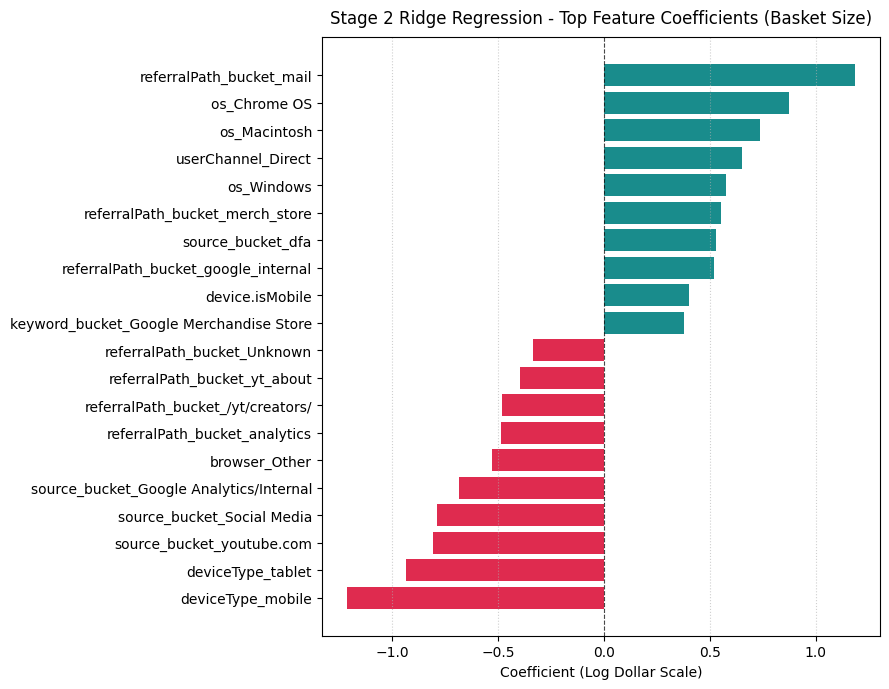

In [121]:
feature_names_reg = stage2_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()
coefs_reg = stage2_pipeline.named_steps['regressor'].coef_

coef_reg_df = pd.DataFrame(
    {
        'feature': feature_names_reg,
        'coefficient': coefs_reg,
        'abs_coef': np.abs(coefs_reg),
    }
).sort_values('coefficient', ascending=False)

# Plot top 10 positive & negative
top_bottom_reg = pd.concat(
    [coef_reg_df.head(10), coef_reg_df.tail(10)]
).sort_values('coefficient')

plt.figure(figsize=(9, 7))
colors = ['crimson' if c < 0 else 'teal' for c in top_bottom_reg['coefficient']]
plt.barh(
    top_bottom_reg['feature'],
    top_bottom_reg['coefficient'],
    color=colors,
    alpha=0.9,
)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title(
    'Stage 2 Ridge Regression - Top Feature Coefficients (Basket Size)',
    fontsize=12,
    pad=10,
)
plt.xlabel('Coefficient (Log Dollar Scale)')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## Stage 2: Spend Volume Estimation & Compound Hurdle Evaluation

With Stage 1 propensity locked, Stage 2 estimates transaction value conditional on conversion ($Y > 0$).

* **Target Normalization:** Transaction values are converted from raw micro-units ($10^6$) to standard currency, followed by a $\log(1 + y)$ transform to stabilize variance.
* **Compound Hurdle Inference:** Expected revenue is computed as:
  $$\mathbb{E}[\text{Revenue} \mid X] = P(\text{Purchased} = 1 \mid X) \times \left(\exp(\widehat{\log(1 + \text{Spend})}) - 1\right)$$

In [122]:
# 1. Compound Hurdle predictions
val_prob_stage1 = stage1_pipeline.predict_proba(X_val_clean)[:, 1]
val_log_spend_stage2 = stage2_pipeline.predict(X_val_clean)

val_log_spend_clipped = np.clip(
    val_log_spend_stage2, 0, y_train_buyers_log.max()
)
val_raw_spend_clipped = np.expm1(val_log_spend_clipped)
final_val_preds_dollars = val_prob_stage1 * val_raw_spend_clipped

val_pred_log_real = np.log1p(np.clip(final_val_preds_dollars, 0, None))

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [123]:
# 2. Baseline Hurdle Metrics
val_rmsle = np.sqrt(mean_squared_error(y_val_log, val_pred_log_real))
val_r2_log = r2_score(y_val_log, val_pred_log_real)

print('=' * 50)
print('HURDLE MODEL BASELINE VALIDATION')
print(f'Validation RMSLE (Log Scale): {val_rmsle:.4f}')
print(f'Validation R² (Log Scale)   : {val_r2_log:.4f}')
print('=' * 50)

HURDLE MODEL BASELINE VALIDATION
Validation RMSLE (Log Scale): 1.0426
Validation R² (Log Scale)   : 0.6330


### Conversion Threshold Calibration ($\tau$)

Multiplying small probabilities against estimated spend introduces residual log noise across thousands of non-purchasing visitors. Setting a hard cutoff $\tau$ zeroes out spend for sub-threshold visits, suppressing background noise.

Optimal Cutoff (τ) : 0.3184
Optimized RMSLE    : 0.9130 (Δ: +0.1296)


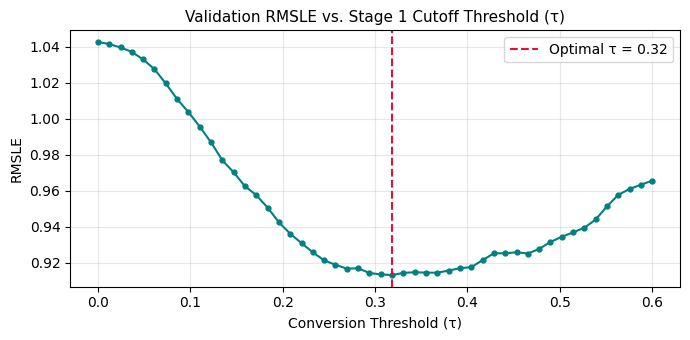

In [124]:
thresholds = np.linspace(0.0, 0.6, 50)
rmsle_scores = [
    np.sqrt(
        mean_squared_error(
            y_val_log,
            np.log1p(
                np.where(val_prob_stage1 >= t, final_val_preds_dollars, 0.0)
            ),
        )
    )
    for t in thresholds
]

best_idx = np.argmin(rmsle_scores)
best_tau = thresholds[best_idx]
best_rmsle = rmsle_scores[best_idx]

print(f'Optimal Cutoff (τ) : {best_tau:.4f}')
print(f'Optimized RMSLE    : {best_rmsle:.4f} (Δ: {val_rmsle - best_rmsle:+.4f})')

plt.figure(figsize=(7, 3.5))
plt.plot(thresholds, rmsle_scores, marker='o', markersize=3.5, color='teal')
plt.axvline(
    best_tau,
    color='crimson',
    linestyle='--',
    label=f'Optimal τ = {best_tau:.2f}',
)
plt.title('Validation RMSLE vs. Stage 1 Cutoff Threshold (τ)', fontsize=11)
plt.xlabel('Conversion Threshold (τ)')
plt.ylabel('RMSLE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [125]:
# 1. Clean test features
X_test_clean = df_test.drop(
    columns=[col for col in features_to_drop if col in df_test.columns]
)


# 2. Stage 1 probability & Stage 2 spend estimation
test_prob = stage1_pipeline.predict_proba(X_test_clean)[:, 1]
test_spend_log = np.clip(
    stage2_pipeline.predict(X_test_clean), 0, y_train_buyers_log.max()
)
test_spend_dollars = np.expm1(test_spend_log)


test_pred_dollars = np.where(
    test_prob >= best_tau, test_prob * test_spend_dollars, 0.0
)
test_pred_raw_units = test_pred_dollars * 1e6

# 4. Generate submission
submission = pd.DataFrame(
    {'id': df_test['sessionId'], 'purchaseValue': test_pred_raw_units}
)

submission.to_csv('submission.csv', index=False)
display(submission.head())

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,id,purchaseValue
0,1494262567,1.895516e+07
1,1491433811,0.000000e+00
2,1489001815,0.000000e+00
3,1510593024,0.000000e+00
4,1481559809,0.000000e+00


In [126]:
print("Training Logistic Regression on Stage 1 (Full Train)...")
stage1_pipeline.fit(X_train_clean, y_train_cls)

stage2_lgbm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_reg),
    ('regressor', LGBMRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=6,
        random_state=42, n_jobs=-1, verbose=-1
    ))
])

print("Training LightGBM on Stage 2...")
stage2_lgbm_pipeline.fit(X_train_buyers_only, y_train_buyers_log)

Training Logistic Regression on Stage 1 (Full Train)...


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.4s finished
/usr/local/lib/python3.12/dist-packages/sklearn/impute/_base.py:572: FutureWarning: Currently, when `keep_empty_feature=False` and `strategy="constant"`, empty features are not dropped. This behaviour will change in version 1.8. Set `keep_empty_feature=True` to preserve this behaviour.
  warnings.warn(


Training LightGBM on Stage 2...


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('target_enc',
                                                  TargetEncoder(target_type='continuous'),
                                                  ['geoNetwork.city',
                                                   'locationCountry',
                                                   'geoNetwork.metro']),
                                                 ('ohe',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['referralPath_bucket',
                                                   'keyword_bucket',
                                                   'source_bucket', 'browser',
                                                   'os', 'userChannel',
                                                   'quarter',...
                                                   'date_is_weekend',
                                                   'is_post_crash', 'is_top_ad',
                                                   'is_AW_campaign',
                                                   'is_google_search_network',
                                                   'hour_sin', 'hour_cos',
                                                   'user_session_count',
                                                   'user_total_spent',
                                                   'user_purchase_value_intent',
                                                   'user_purchase_rate'])],
                                   verbose_feature_names_out=False)),
                ('regressor',
                 LGBMRegressor(learning_rate=0.05, max_depth=6,
                               n_estimators=150, n_jobs=-1, random_state=42,
                               verbose=-1))])

In [127]:
# 2. Split holdout perfectly in half (50% for τ tuning, 50% for blind testing)
X_calib, X_test, y_calib_log, y_test_log = train_test_split(
    X_val_clean, y_val_log, test_size=0.5, random_state=42
)
y_test_raw = np.expm1(y_test_log)

# 3. Calibrate Threshold (τ) strictly on the Calibration Slice
calib_prob = stage1_pipeline.predict_proba(X_calib)[:, 1]
calib_spend_lgbm = np.clip(stage2_lgbm_pipeline.predict(X_calib), 0, y_train_buyers_log.max())

best_tau = 0.01
best_rmsle = float('inf')
for tau in np.linspace(0.1, 0.5, 100):
    preds = np.where(calib_prob >= tau, calib_prob * np.expm1(calib_spend_lgbm), 0.0)
    rmsle = np.sqrt(mean_squared_error(y_calib_log, np.log1p(preds)))
    if rmsle < best_rmsle:
        best_rmsle = rmsle
        best_tau = tau

print(f"Optimal τ learned from Calibration Slice: {best_tau:.4f}\n")

Optimal τ learned from Calibration Slice: 0.3141



/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [128]:
# 4. Generate Predictions on the unseen Test Slice
test_prob = stage1_pipeline.predict_proba(X_test)[:, 1]

# Stage 2 Predictions
test_ridge_raw = np.expm1(np.clip(stage2_pipeline.predict(X_test), 0, y_train_buyers_log.max()))
test_lgbm_raw = np.expm1(np.clip(stage2_lgbm_pipeline.predict(X_test), 0, y_train_buyers_log.max()))

# 5. Calculate all Baseline & Model Scenarios
results = {
    "1. Predict-Zero Baseline": np.zeros_like(y_test_raw),
    "2. Single-Stage (LGBM)": test_lgbm_raw, # Over-predicts massively without Hurdle
    "3. Hurdle Model (Ridge)": np.where(test_prob >= best_tau, test_prob * test_ridge_raw, 0.0),
    "4. Hurdle Model (LGBM)": np.where(test_prob >= best_tau, test_prob * test_lgbm_raw, 0.0)
}

# 6. Evaluate and Print
print("=" * 75)
print(f"{'MODEL PIPELINE':<25} | {'RMSLE':<8} | {'R² (Log)':<8} | {'R² (Raw)':<8}")
print("-" * 75)

for name, preds_raw in results.items():
    preds_log = np.log1p(preds_raw)
    
    rmsle = np.sqrt(mean_squared_error(y_test_log, preds_log))
    r2_log = r2_score(y_test_log, preds_log)
    r2_raw = r2_score(y_test_raw, preds_raw)
    
    print(f"{name:<25} | {rmsle:<8.4f} | {r2_log:<8.4f} | {r2_raw:<8.4f}")
print("=" * 75)

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


MODEL PIPELINE            | RMSLE    | R² (Log) | R² (Raw)
---------------------------------------------------------------------------
1. Predict-Zero Baseline  | 1.9062   | -0.2313  | -0.0245 
2. Single-Stage (LGBM)    | 3.0912   | -2.2380  | 0.2664  
3. Hurdle Model (Ridge)   | 0.9235   | 0.7110   | -5.2023 
4. Hurdle Model (LGBM)    | 0.8690   | 0.7441   | 0.2940  


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


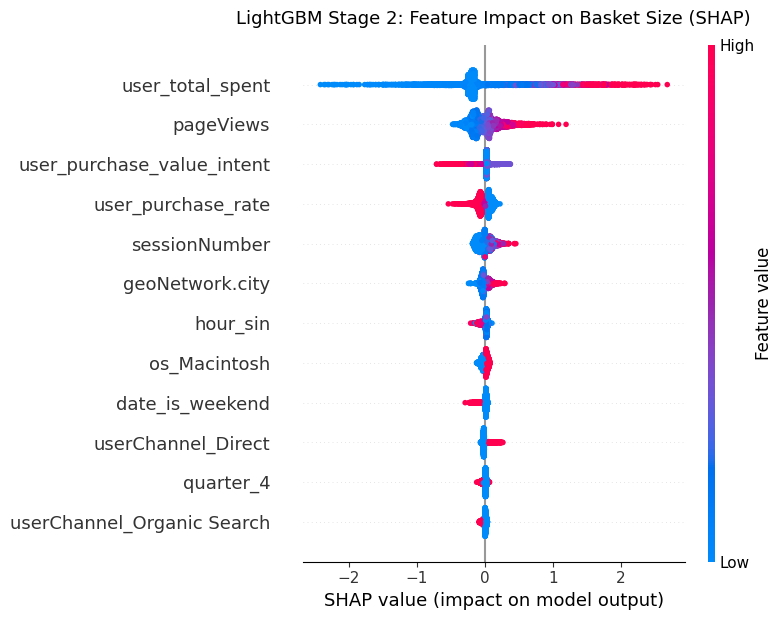

In [129]:
import shap
import matplotlib.pyplot as plt

# 1. Extract the trained LightGBM model and preprocessor from the pipeline
preprocessor = stage2_lgbm_pipeline.named_steps['preprocessor']
lgbm_model = stage2_lgbm_pipeline.named_steps['regressor']

# 2. Transform only the confirmed buyers in validation to analyze what drives their spend
X_val_buyers = X_val_clean[y_val_cls == 1]
X_val_transformed = preprocessor.transform(X_val_buyers)

# 3. Calculate SHAP values (TreeExplainer is highly optimized for LightGBM)
explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_val_transformed)

# 4. Generate the SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, 
    X_val_transformed, 
    max_display=12, 
    show=False
)
plt.title("LightGBM Stage 2: Feature Impact on Basket Size (SHAP)", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

###  What Drives Basket Size ?

To provide transparent business insights, we applied SHAP (SHapley Additive exPlanations) to the LightGBM Stage 2 model. While Stage 1 determines *if* a user will buy, this analysis reveals what dictates *how much* they spend once they decide to check out:

* **Historical Loyalty is the Ultimate Predictor:** A user's past cumulative spend (`user_total_spent`) dominates the model's decision-making. High historical spend (red dots) heavily drives up predicted revenue, proving that retention and repeat high-value buyers are the core revenue engine.
* **Deep Engagement Signals Intent:** Higher `pageViews` (red dots) strongly correlate with larger cart values. Visitors buying high-ticket items or bulk orders spend significantly more time browsing before completing a transaction.
* **Frequency vs. Volume Trade-off:** High `user_purchase_rate` (red dots) pushes the predicted spend down. This indicates that highly frequent buyers are typically purchasing smaller, single items rather than making large bulk orders.
* **The Mobile Penalty:** The hardware factor is represented via `device.isMobile`. Mobile sessions (red dots) consistently exert a negative drag on the final basket size, while non-mobile/desktop sessions (blue dots) push the value up. Even among confirmed buyers, mobile users stick to lower-value purchases, highlighting a potential friction point in the mobile checkout experience.